# **Classification With Model Interpretation**

### **Importing Modules**


In [6]:
import numpy as np
import pandas as pd
from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
import os
import missingno as msno
import shap
shap.initjs()
import lime
from lime import lime_tabular

from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV, GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import make_scorer, cohen_kappa_score

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn import ensemble
from sklearn.ensemble import (
    RandomForestClassifier, 
    GradientBoostingClassifier, 
    VotingClassifier
)
from xgboost import XGBClassifier
from IPython.display import display, HTML
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    roc_auc_score,
    f1_score,
    precision_score,
    recall_score,
    log_loss,
    cohen_kappa_score,
    r2_score,
    classification_report
)
from pprint import pprint
from mlxtend.classifier import StackingClassifier
import warnings
warnings.simplefilter('ignore')

### **Reading Data**

In [7]:
path = Path(r"D:\\DS Projects\\Prudential-Life-Insurance-Assessment\\Raw_Data")
df = pd.read_csv(path / "data.csv")
print(df.shape)
df.head()

(79146, 128)


,Id,Product_Info_1,Product_Info_2,Product_Info_3,Product_Info_4,Product_Info_5,Product_Info_6,Product_Info_7,Ins_Age,Ht,...,Medical_Keyword_40,Medical_Keyword_41,Medical_Keyword_42,Medical_Keyword_43,Medical_Keyword_44,Medical_Keyword_45,Medical_Keyword_46,Medical_Keyword_47,Medical_Keyword_48,Response
0,2,1,D3,10,0.076923,2,1,1,0.641791,0.581818,...,0,0,0,0,0,0,0,0,0,8.0
1,5,1,A1,26,0.076923,2,3,1,0.059701,0.600000,...,0,0,0,0,0,0,0,0,0,4.0
2,6,1,E1,26,0.076923,2,3,1,0.029851,0.745455,...,0,0,0,0,0,0,0,0,0,8.0
3,7,1,D4,10,0.487179,2,3,1,0.164179,0.672727,...,0,0,0,0,0,0,0,0,0,8.0
4,8,1,D2,26,0.230769,2,3,1,0.417910,0.654545,...,0,0,0,0,0,0,0,0,0,8.0


### **Shape**

In [8]:
df.shape

(79146, 128)

### **Distribution of Target Variable**

In [9]:
df['Response'].value_counts()

Response
8.0    19489
6.0    11233
7.0     8027
2.0     6552
1.0     6207
5.0     5432
4.0     1428
3.0     1013
Name: count, dtype: int64

> **Class imbalance can be seen here. Also there 8 categories, lets combine them to 3 categories**


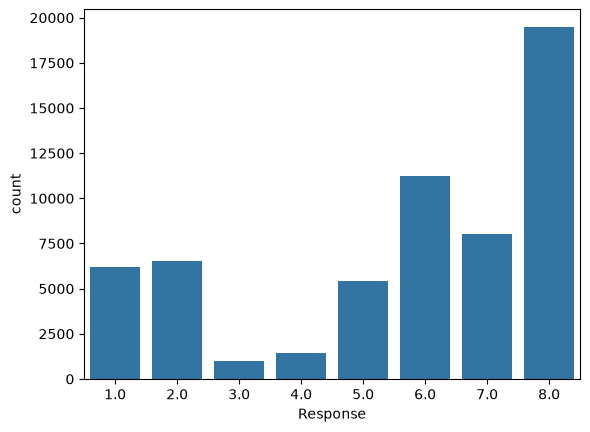

In [10]:
sns.countplot(x=df['Response']);

**Response 8 has highest values and 3 has the least**

### **Processing Target Variable**

In [11]:
#Combining the Categores to 3 categories
df['Modified_Response']  = df['Response'].apply(lambda x : 0 if x<=7 and x>=0 else (1 if x==8 else -1))

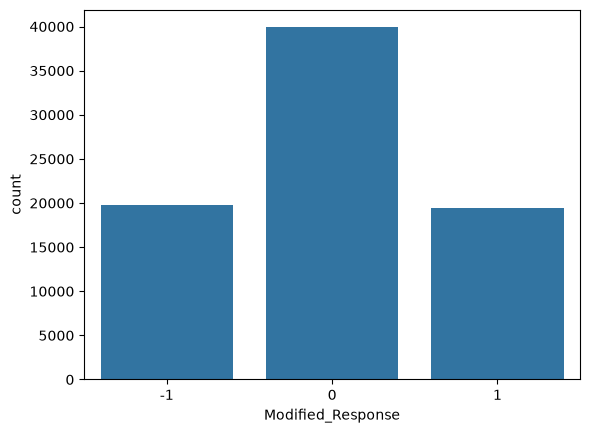

In [12]:
sns.countplot(x= df['Modified_Response']);

> **Still some imbalance can be seen**

### **Removing old target variable**

In [13]:
# Dropping old response columns
df.drop('Response',axis = 1, inplace=True)

### **Making categorical and numerical columns list**

In [14]:
# Making lists with categorical and numerical features.
categorical =  [col for col in df.columns if df[col].dtype =='object']

numerical = categorical =  [col for col in df.columns if df[col].dtype !='object']

### **Visualizations On Categorical Features**

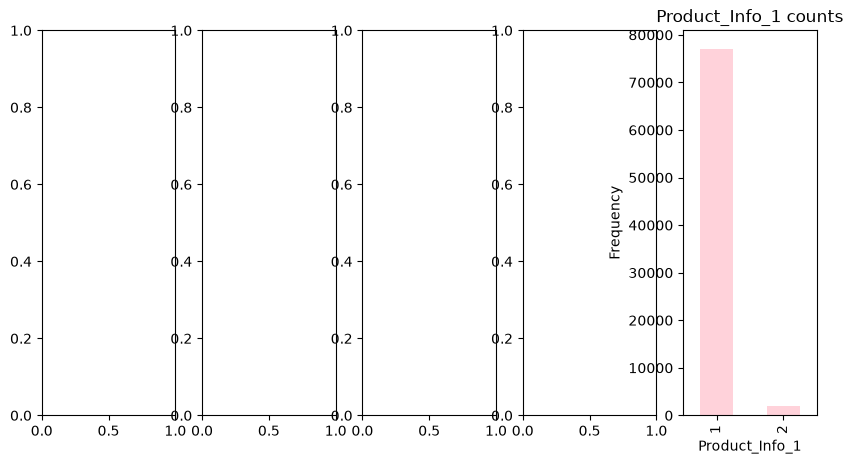

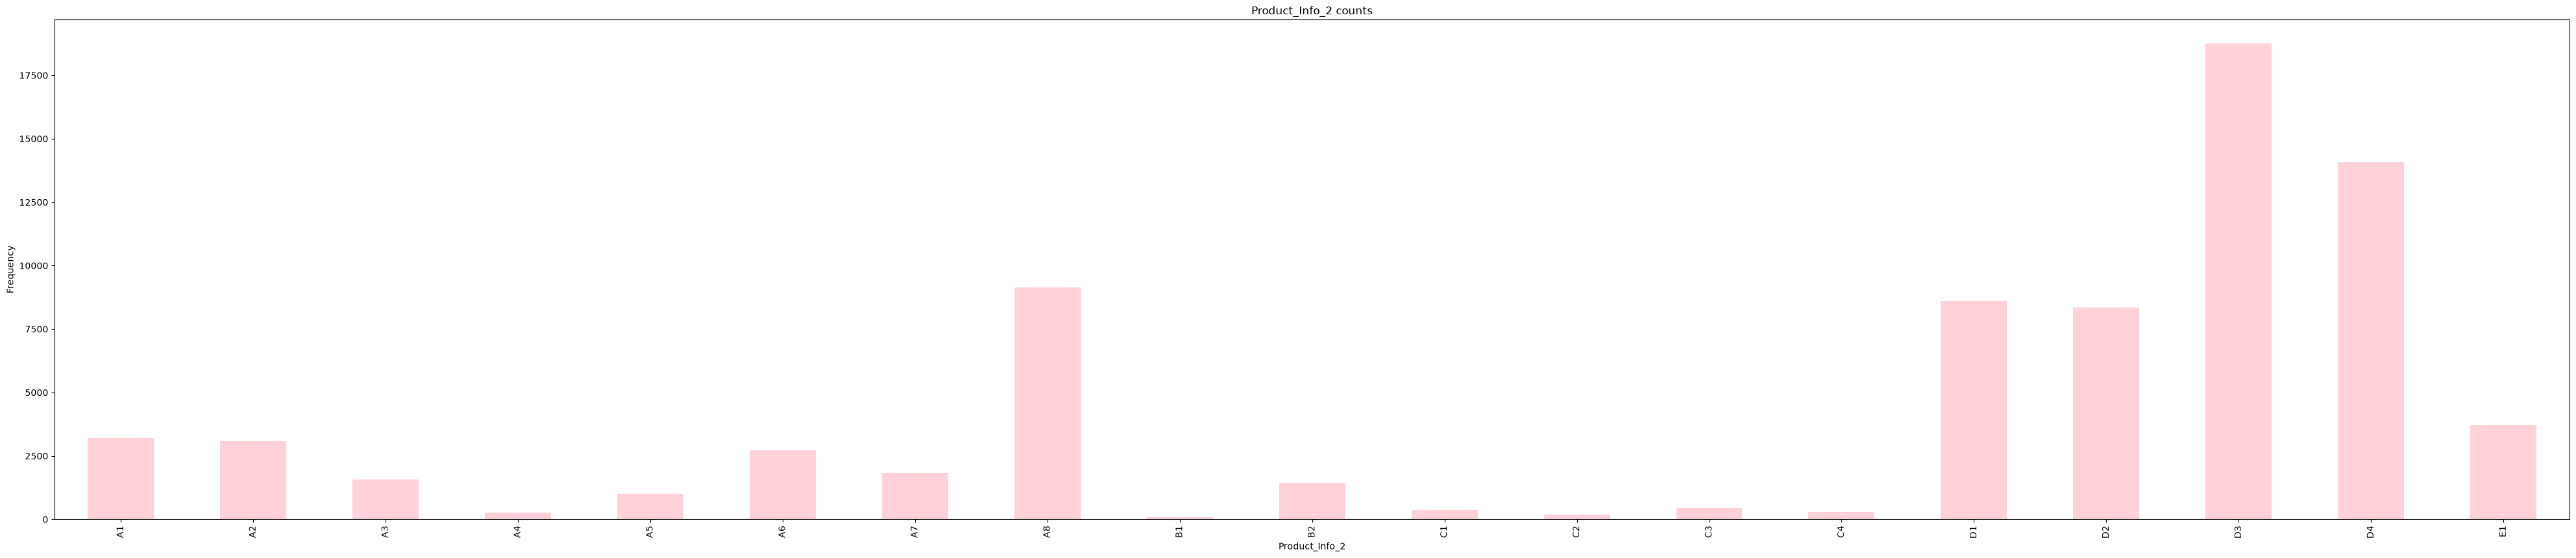

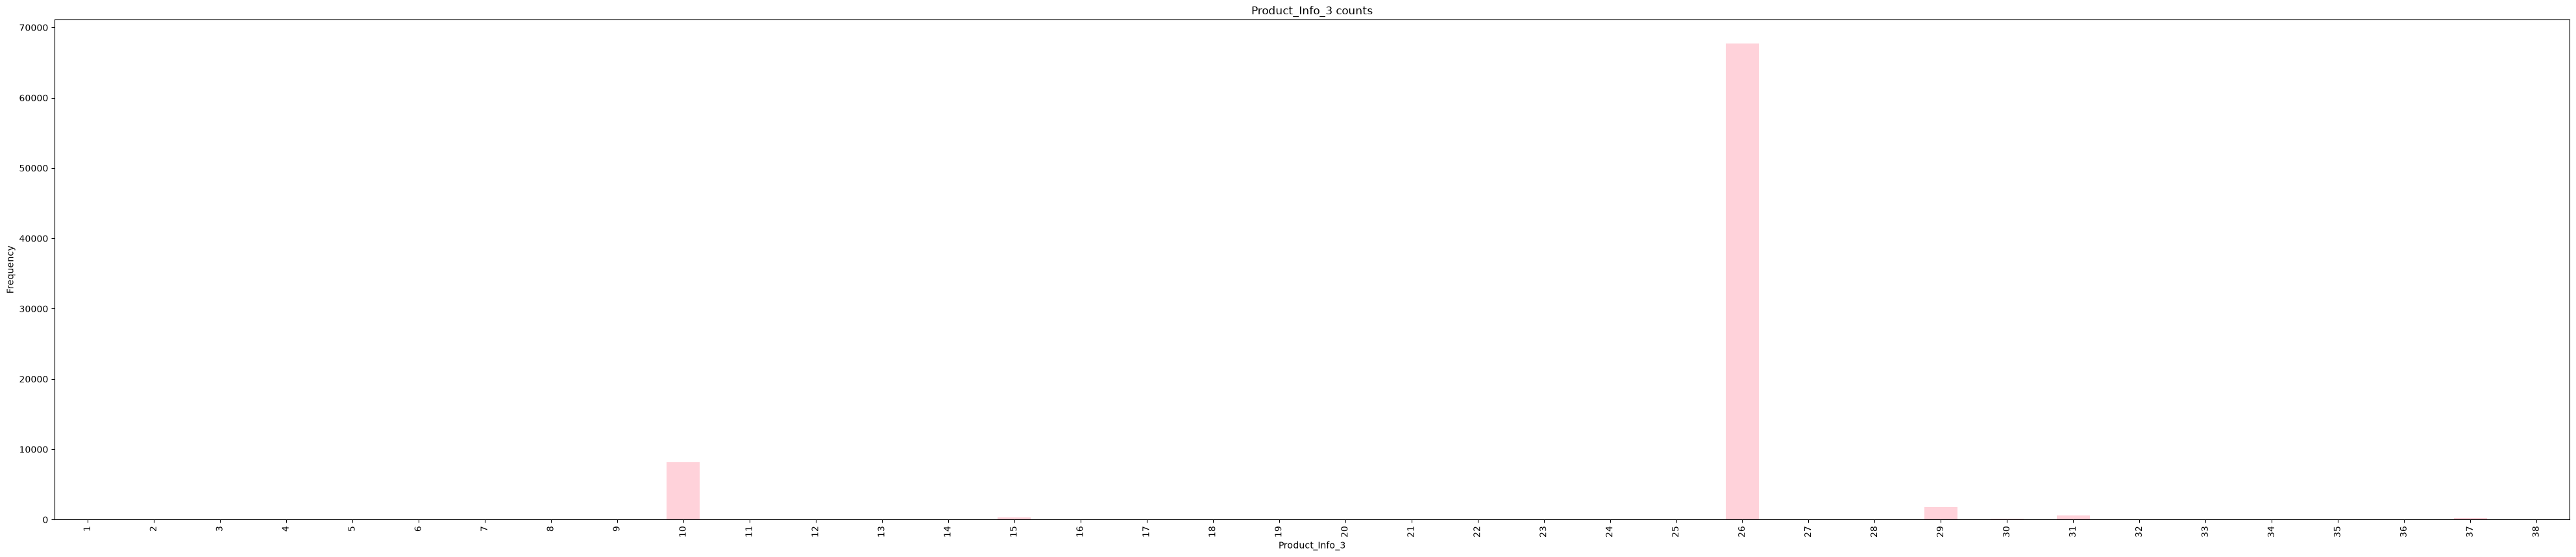

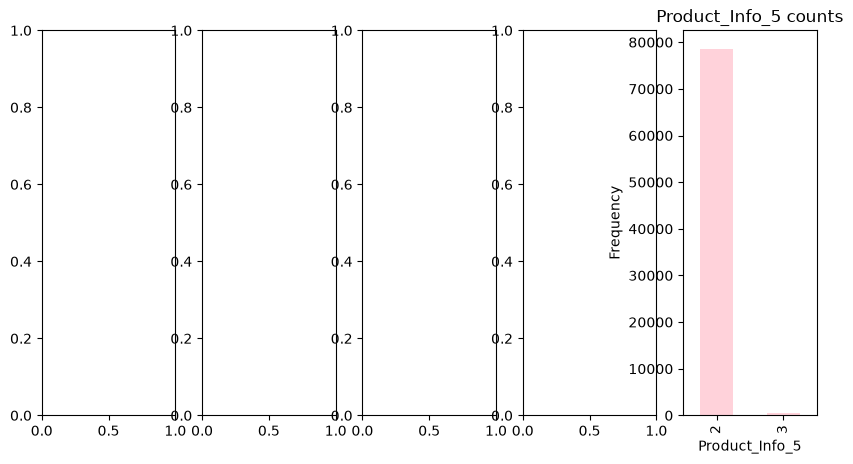

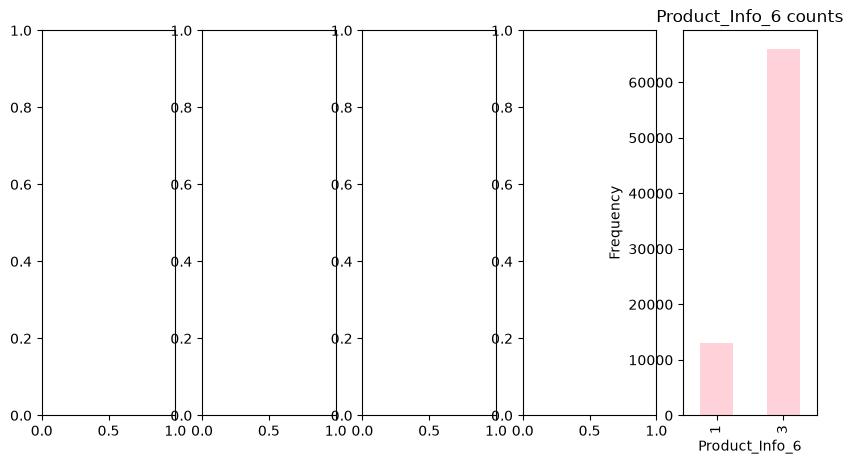

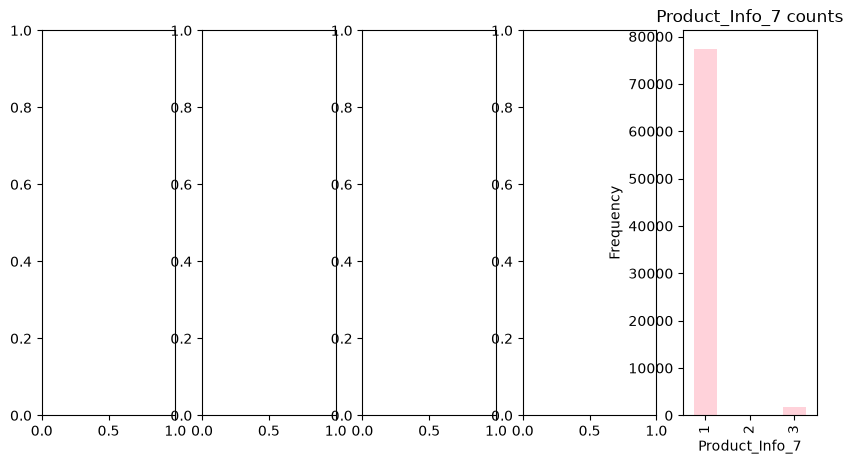

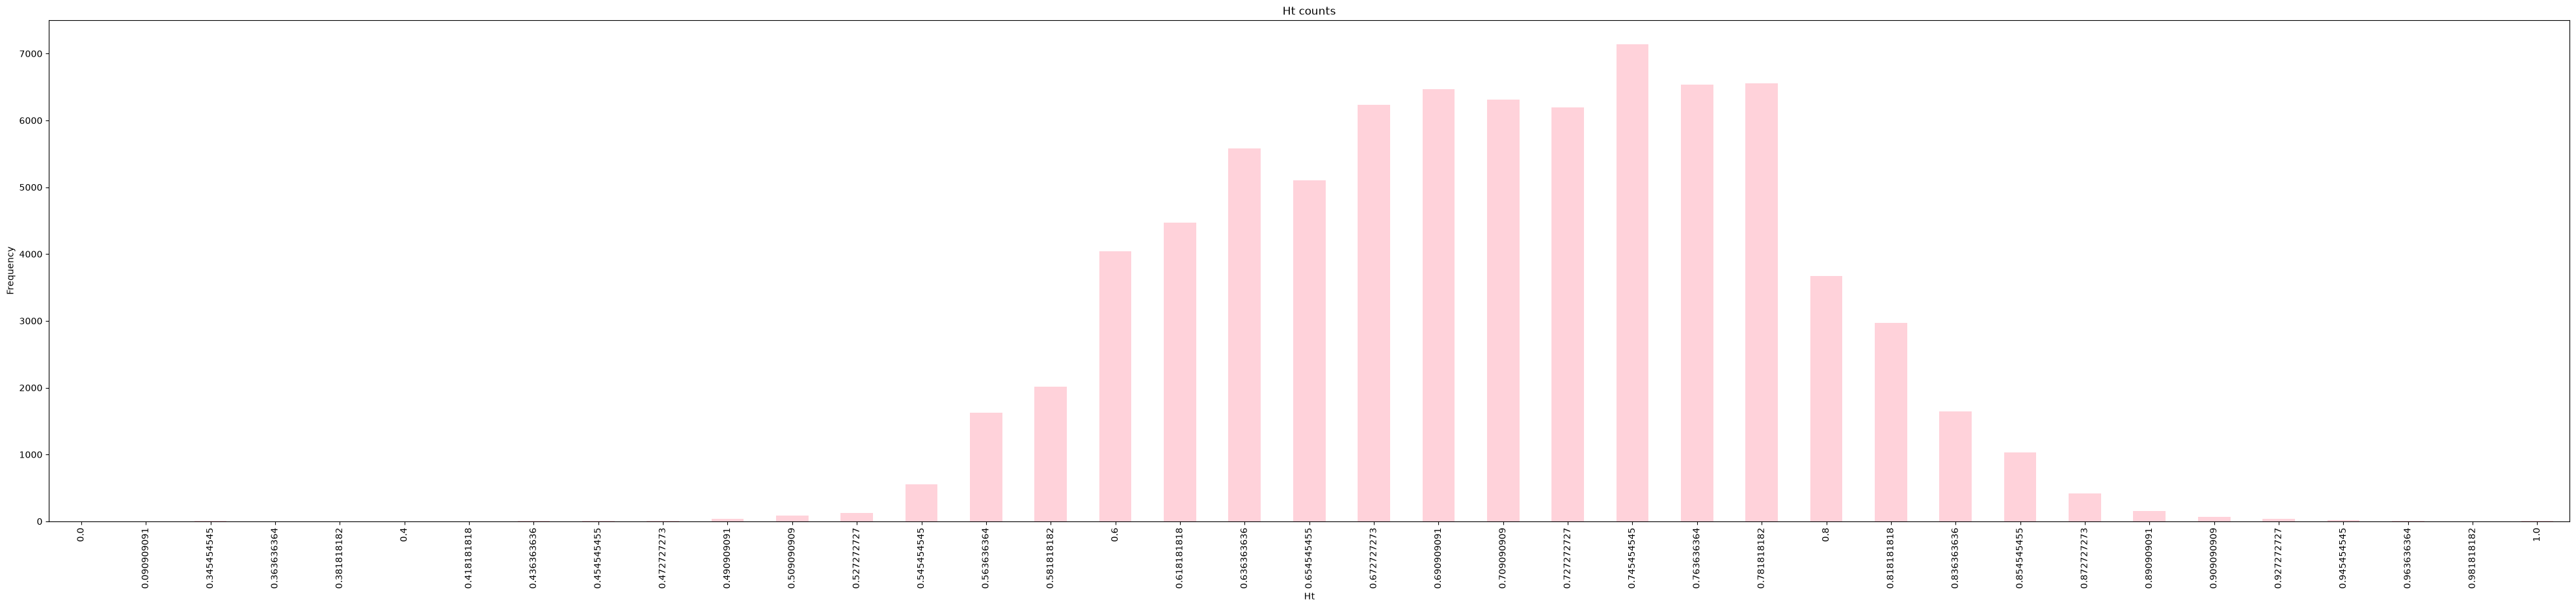

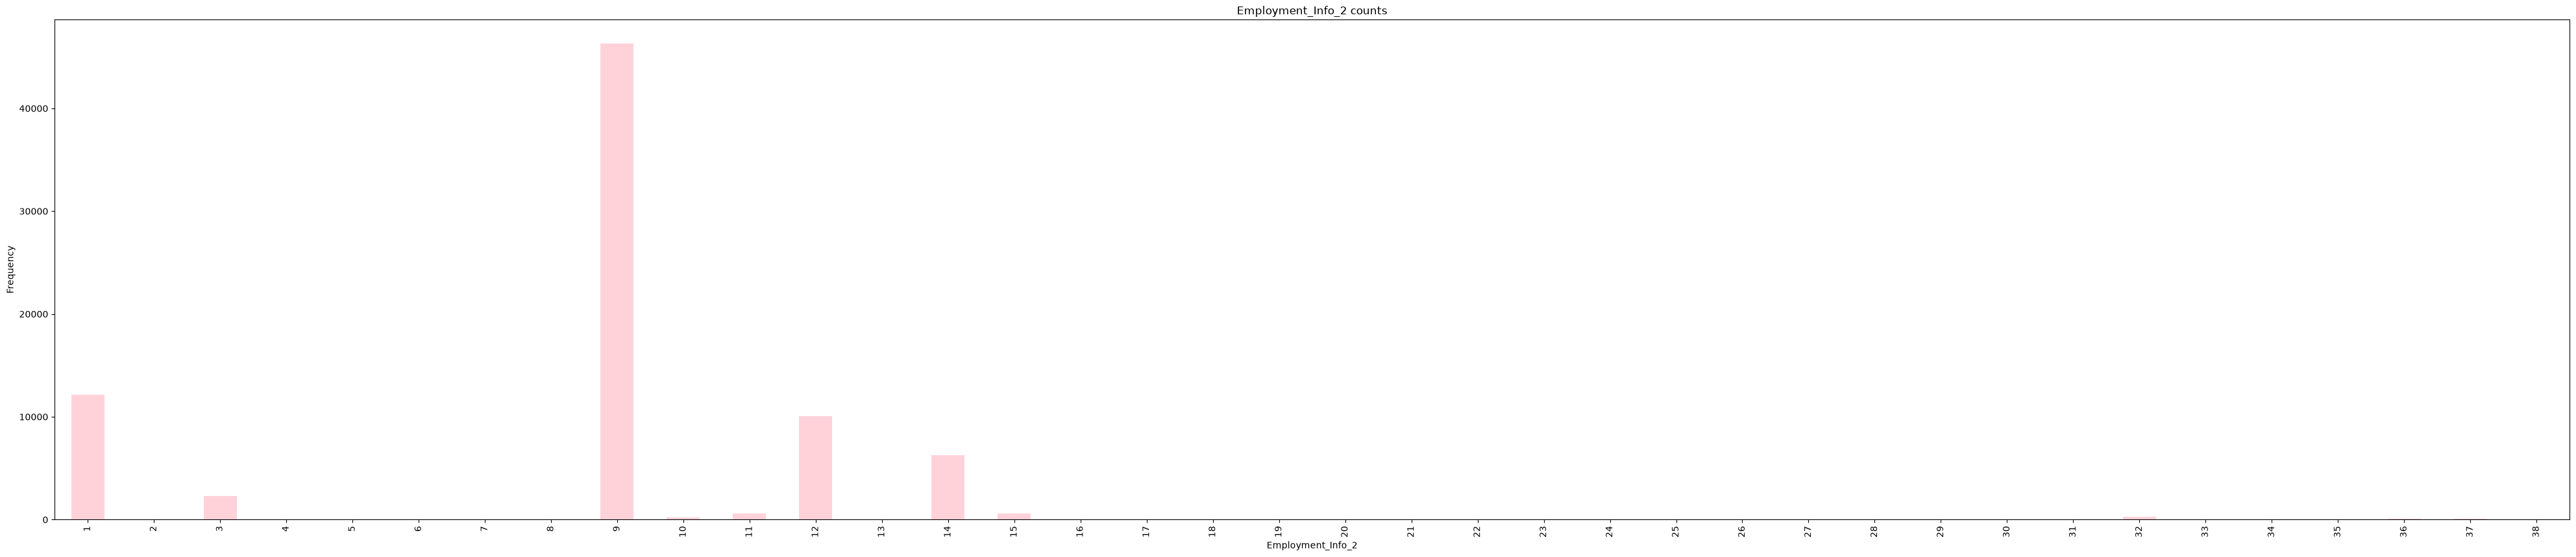

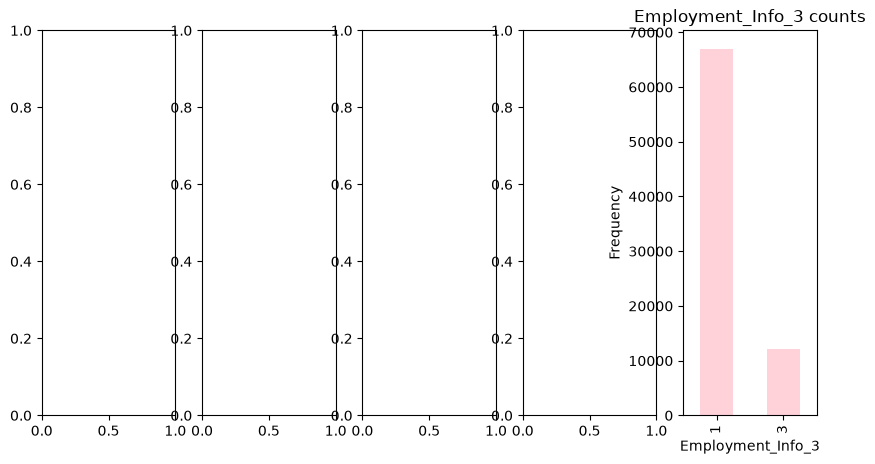

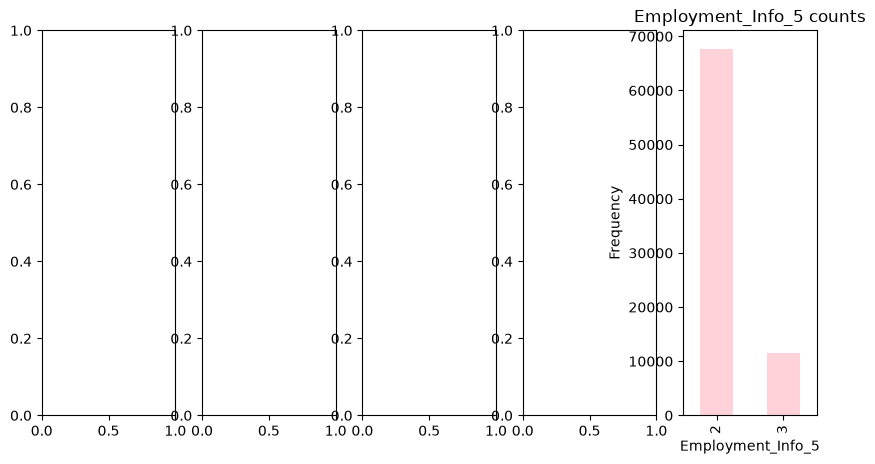

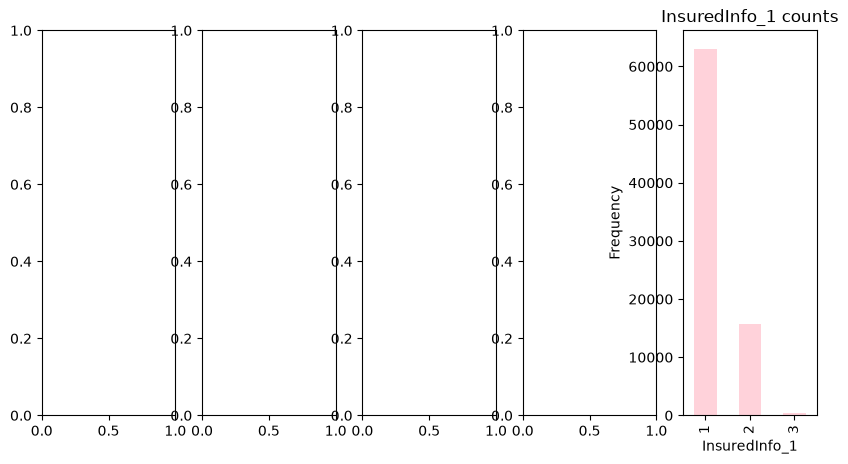

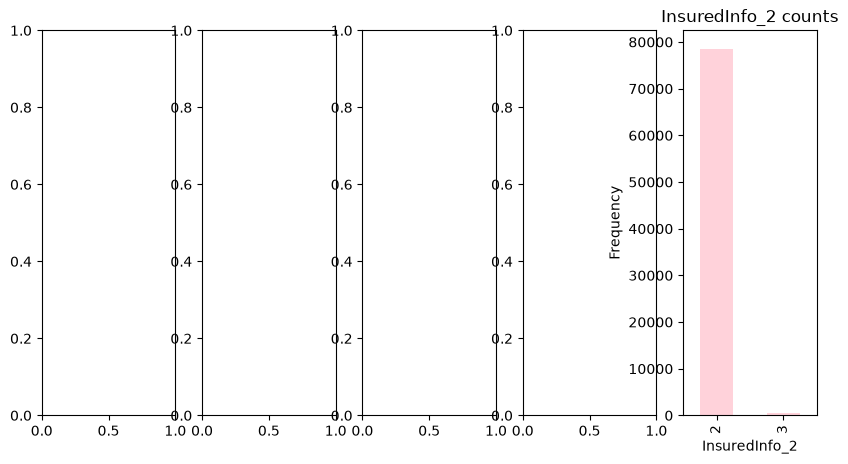

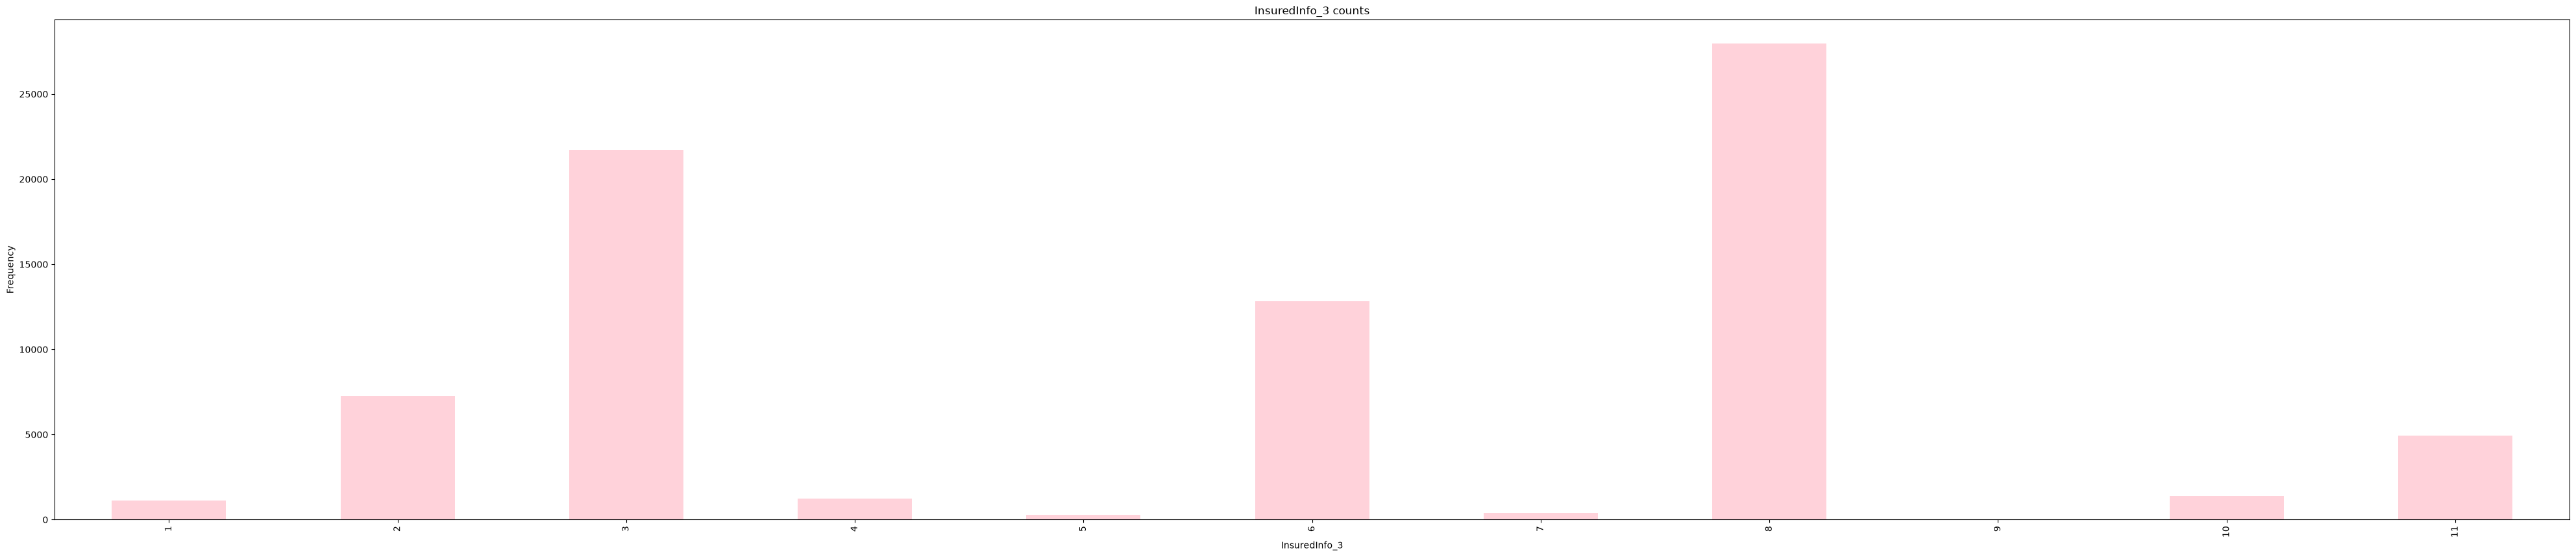

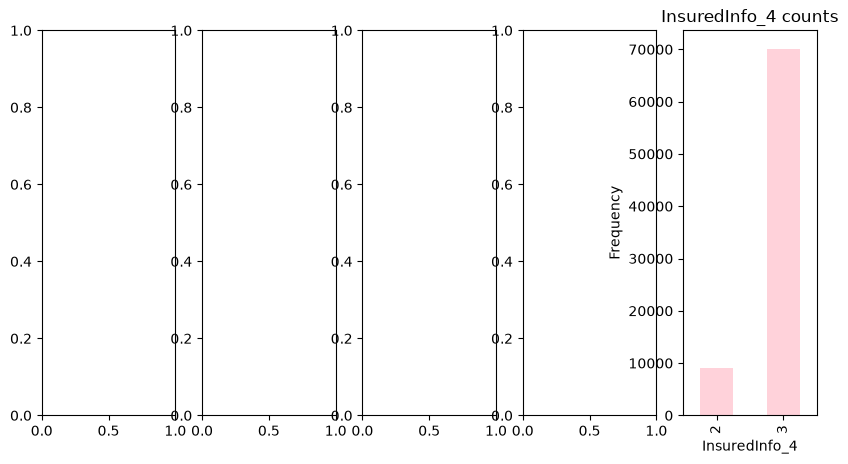

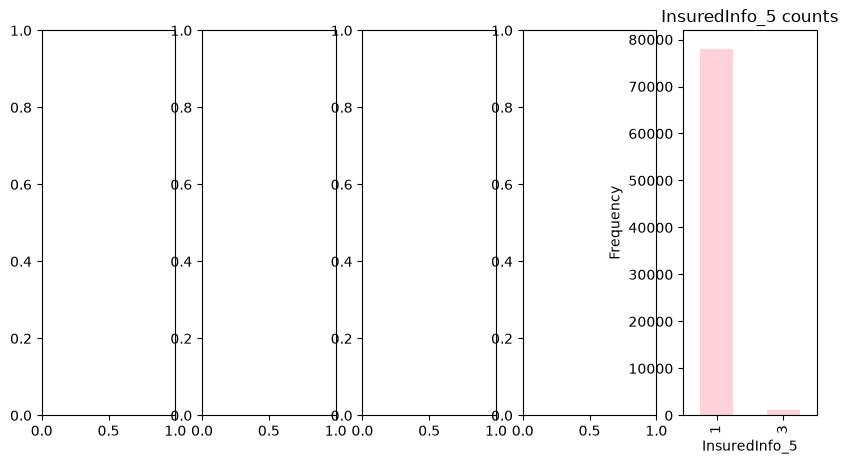

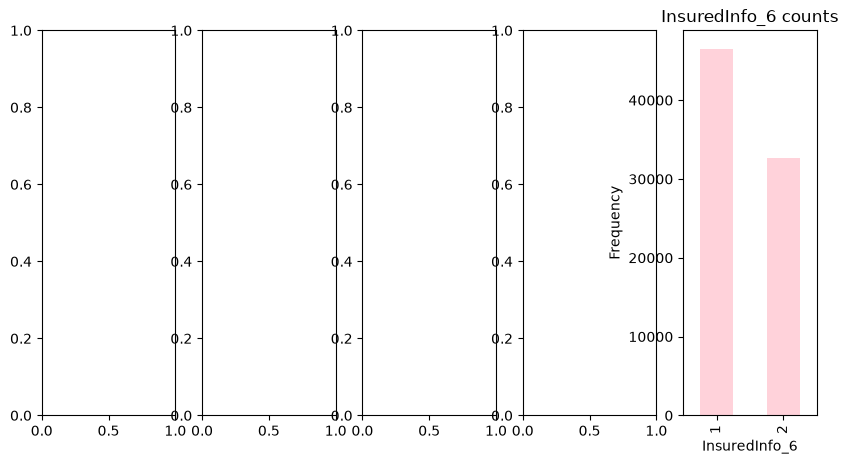

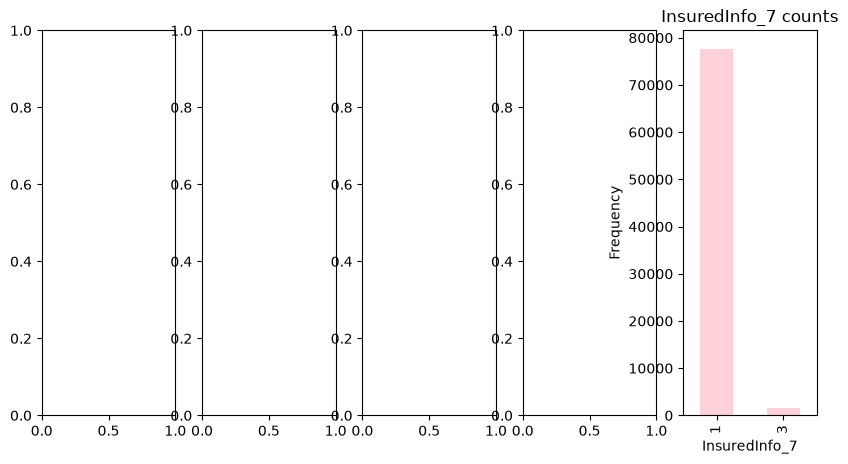

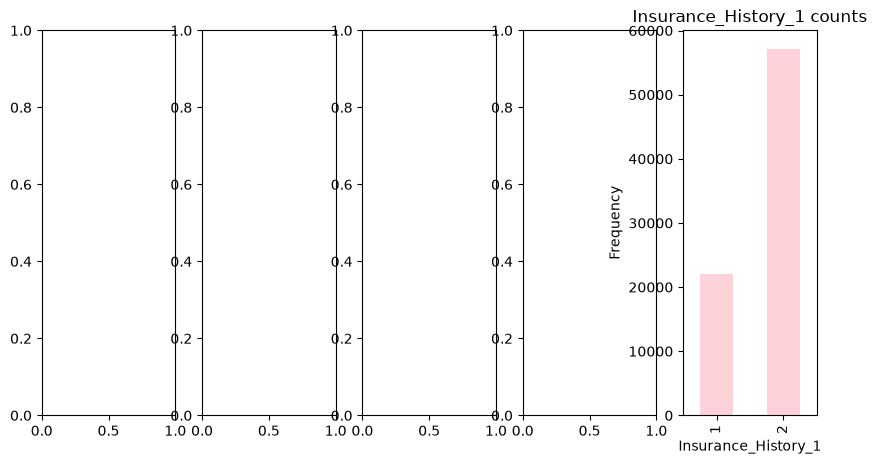

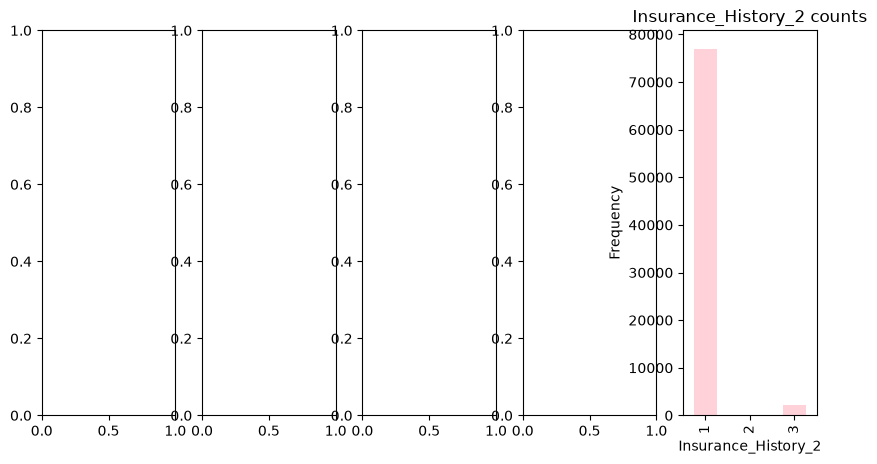

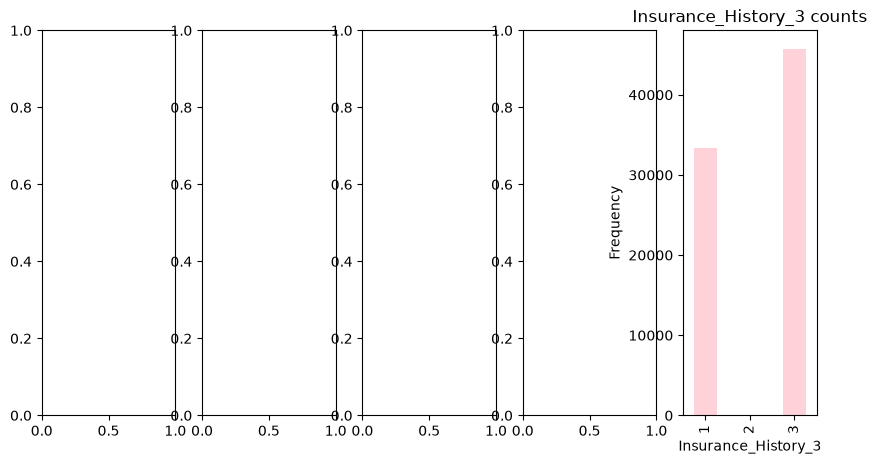

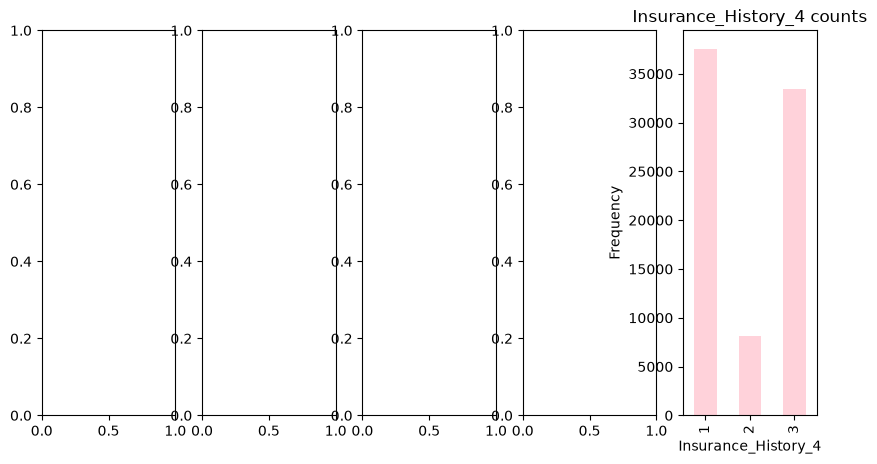

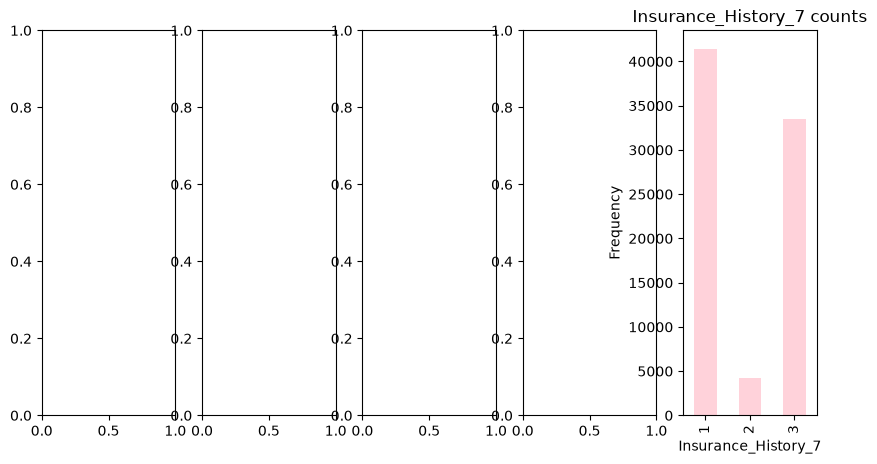

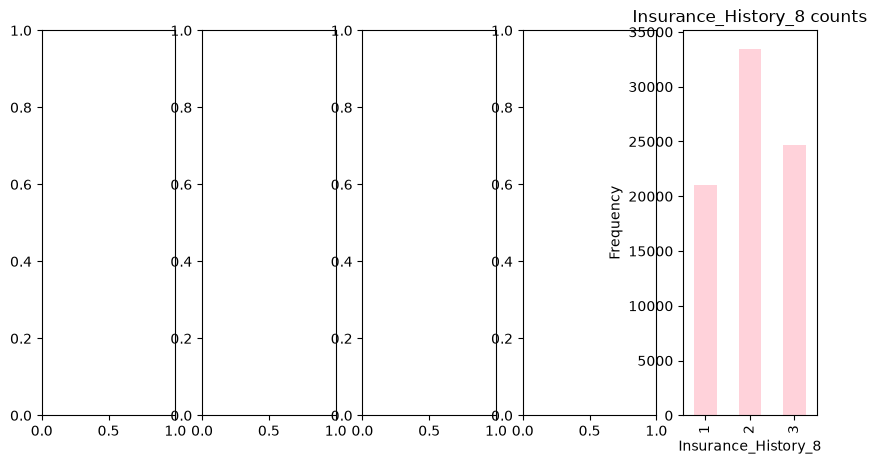

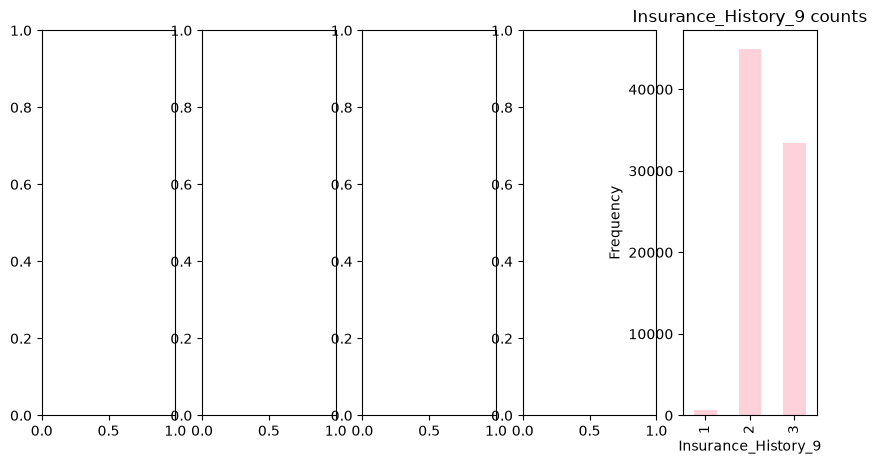

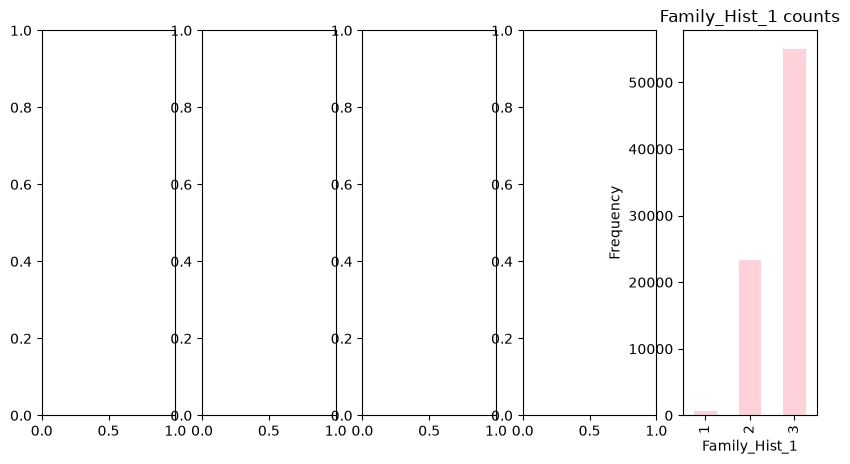

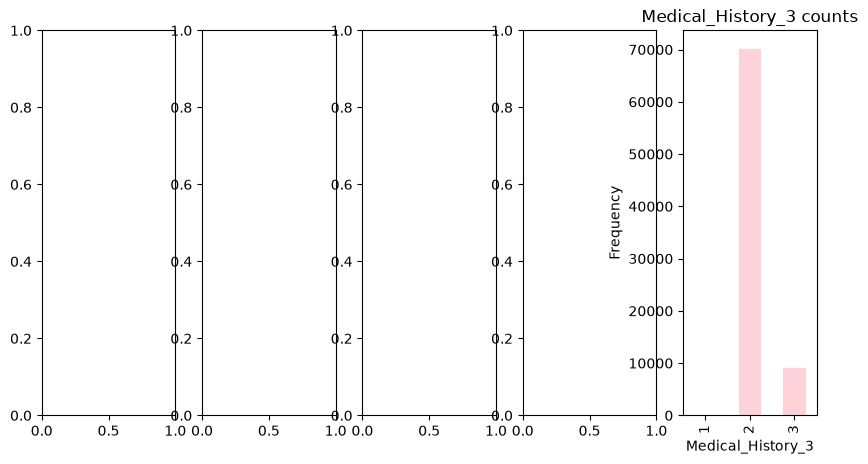

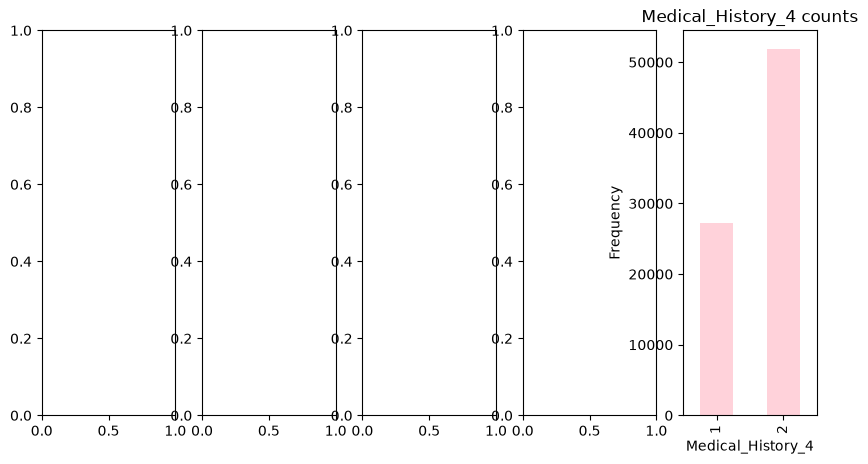

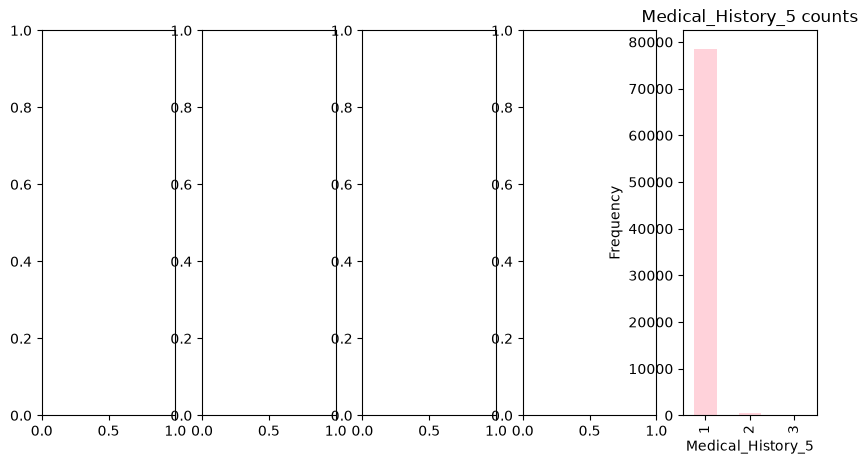

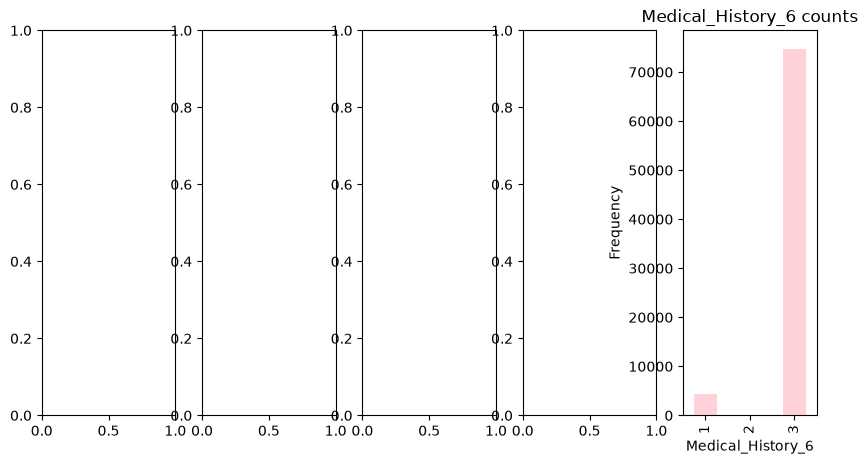

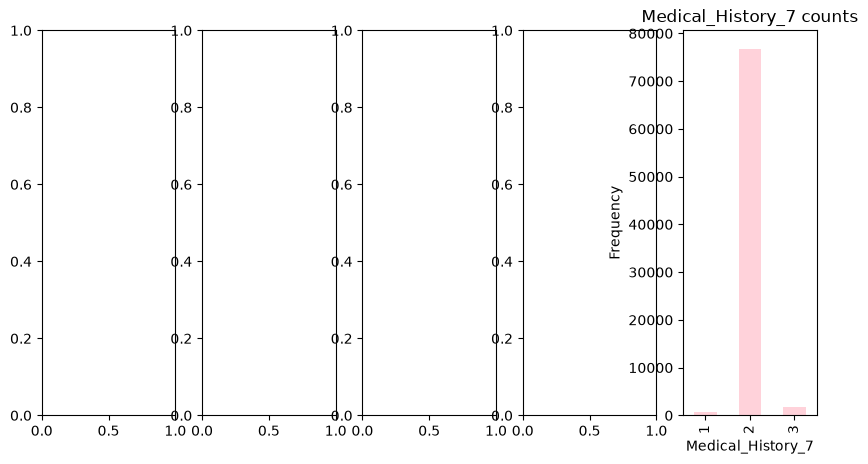

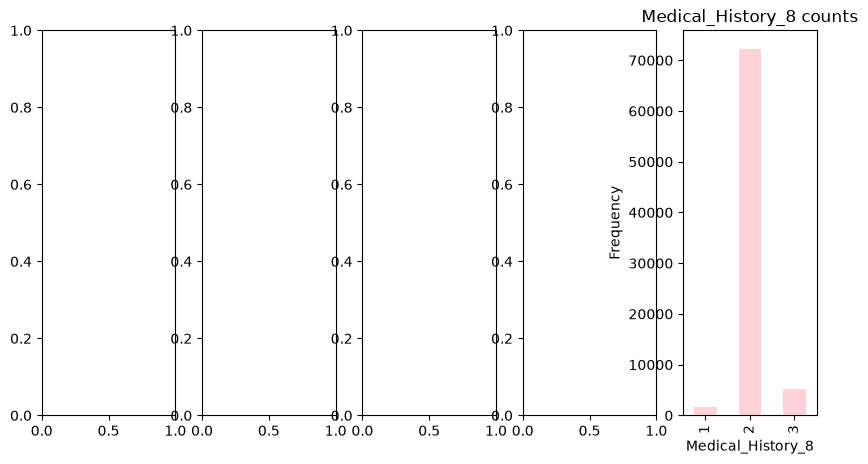

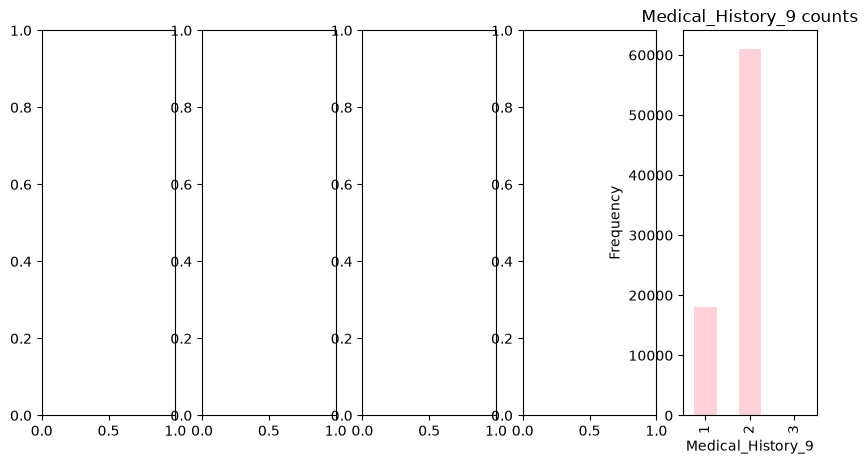

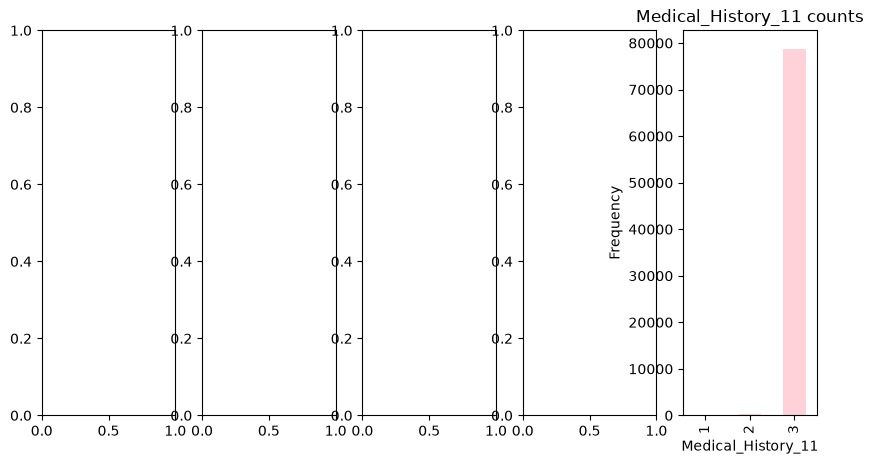

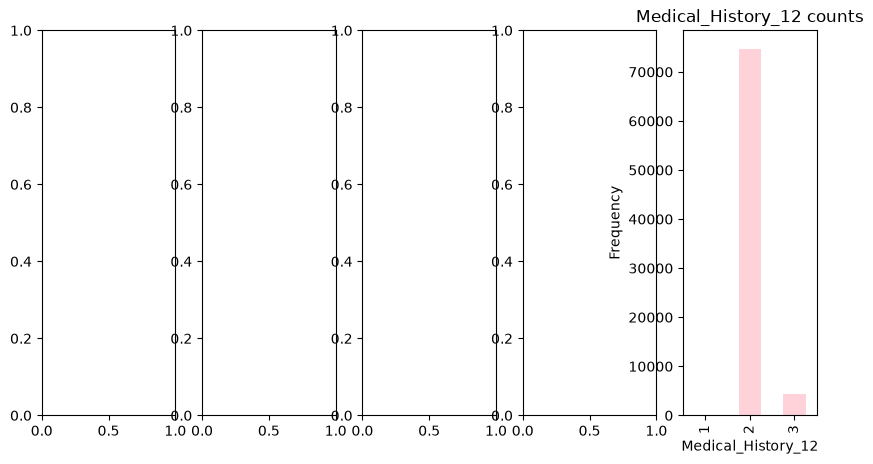

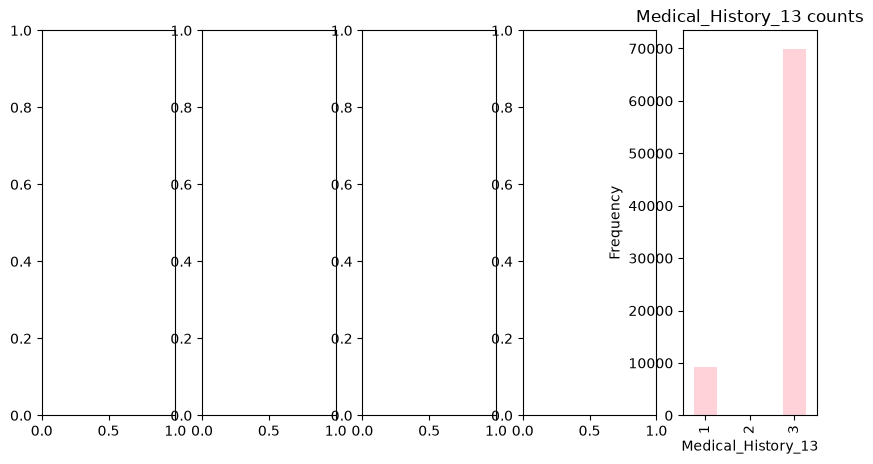

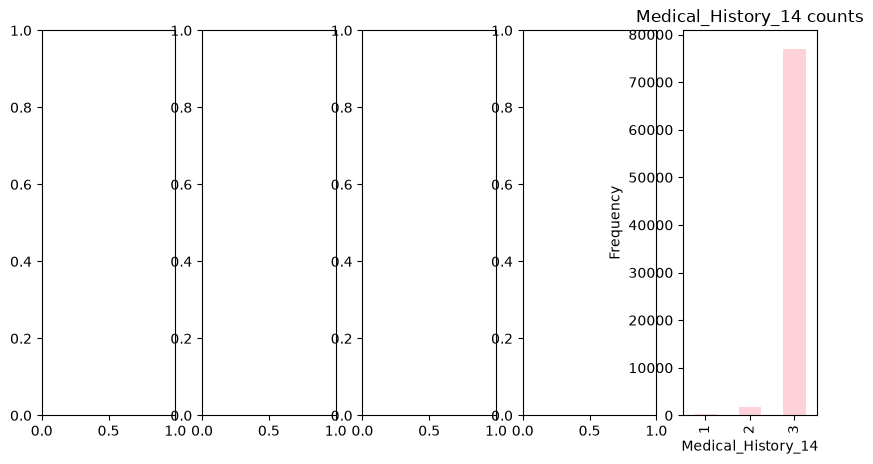

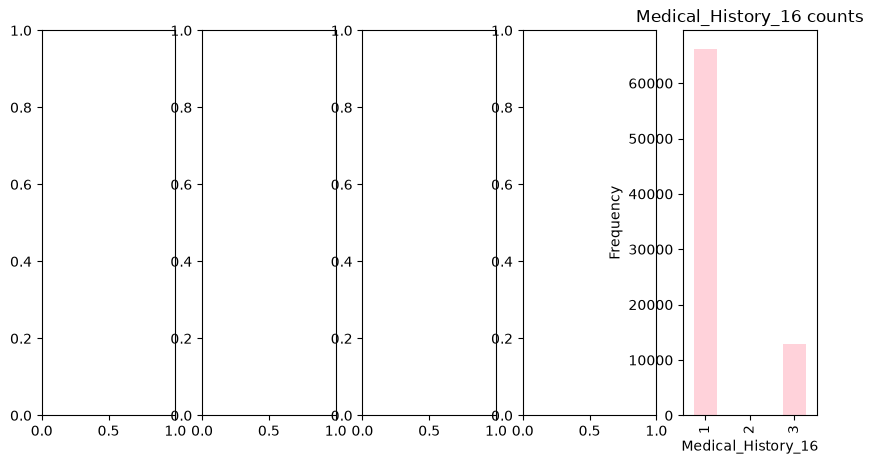

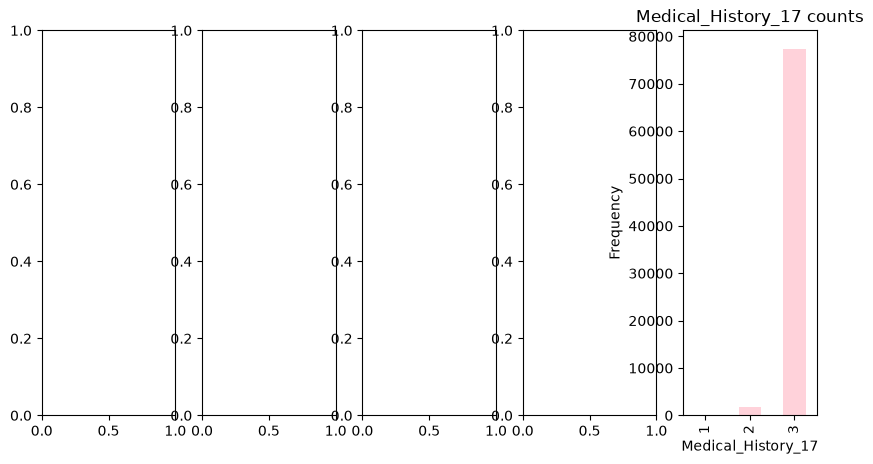

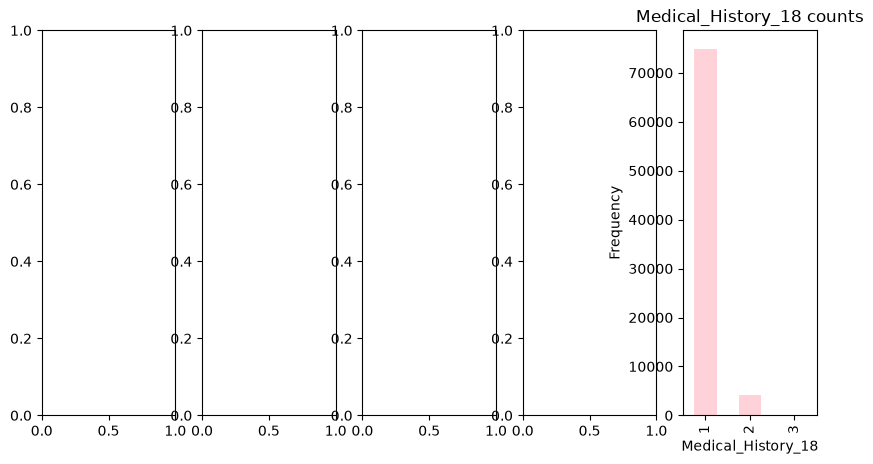

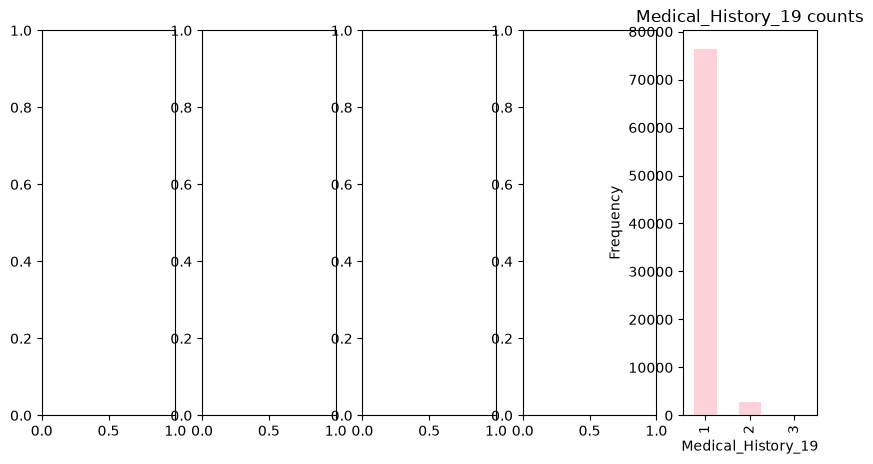

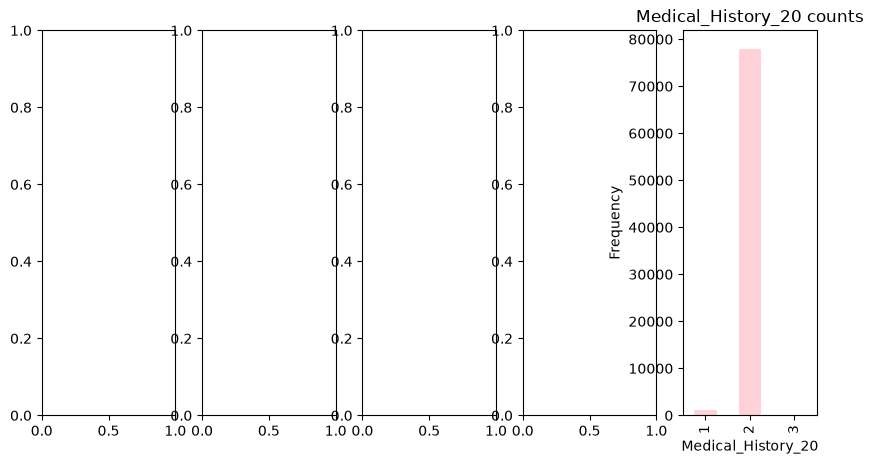

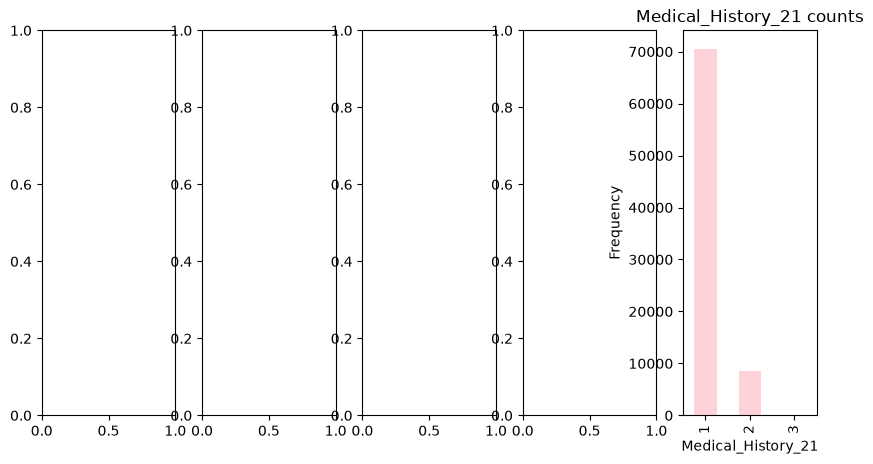

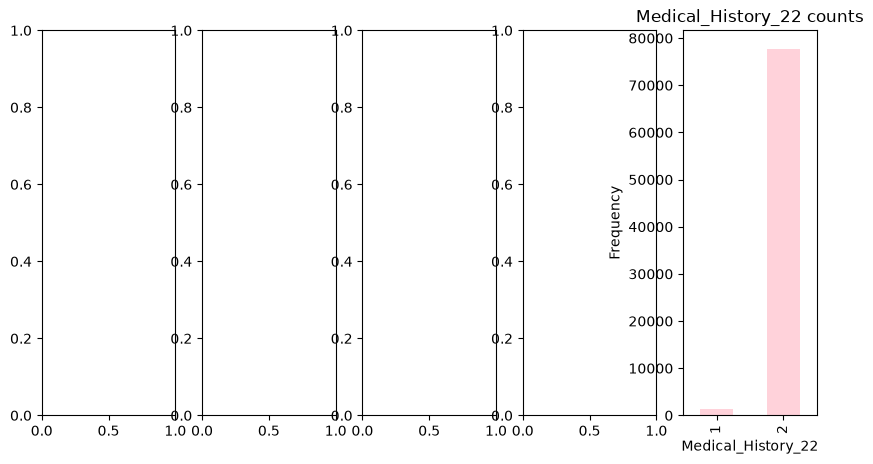

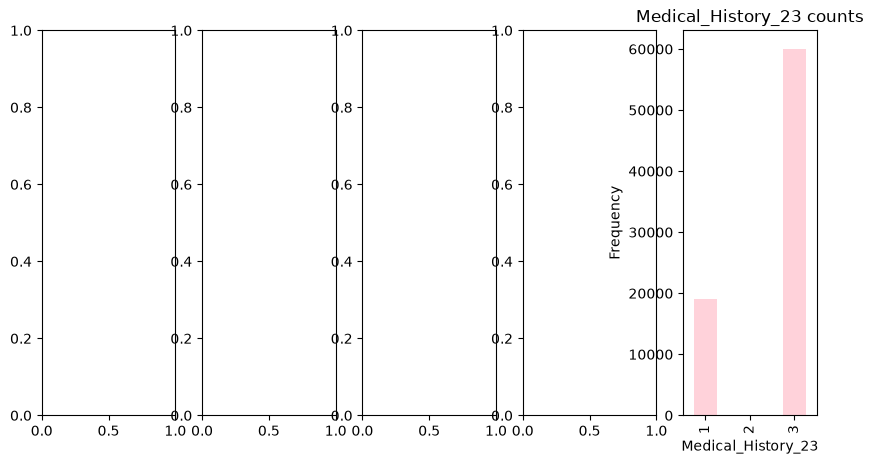

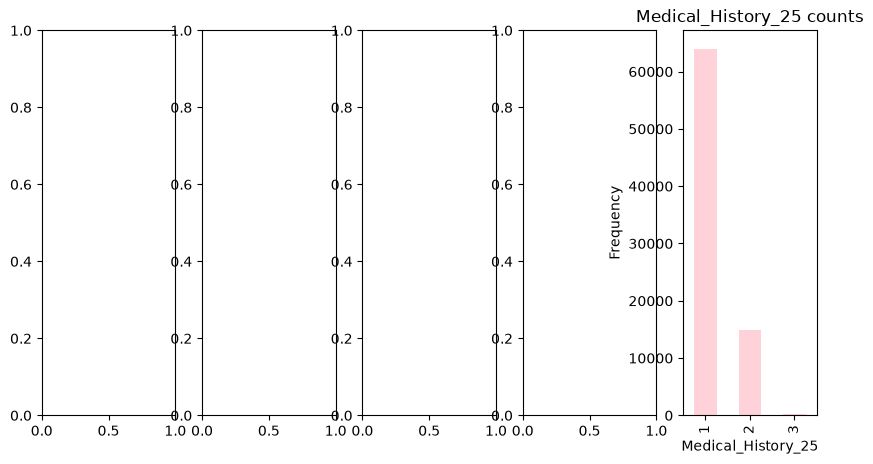

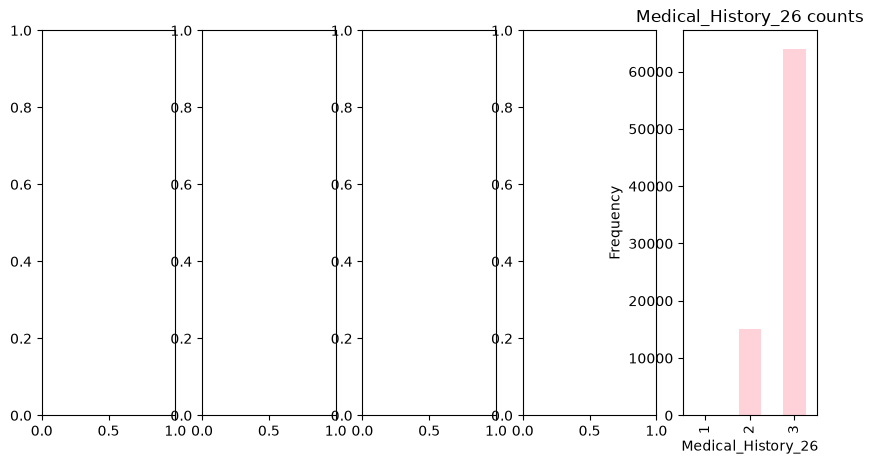

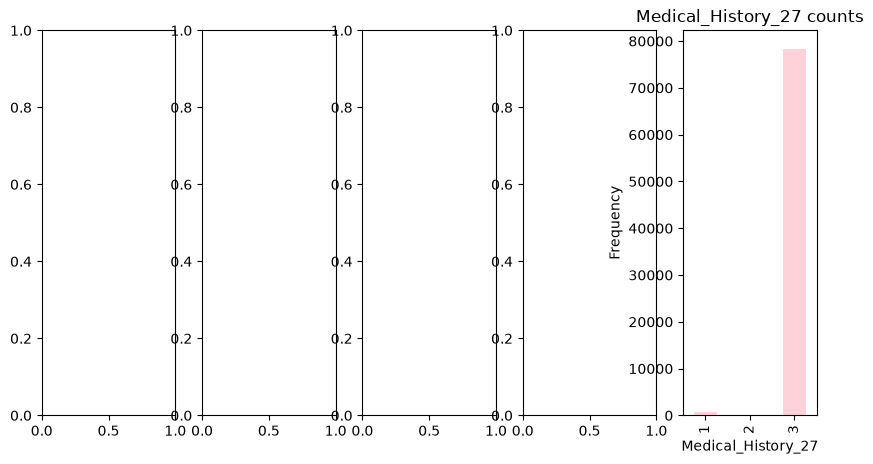

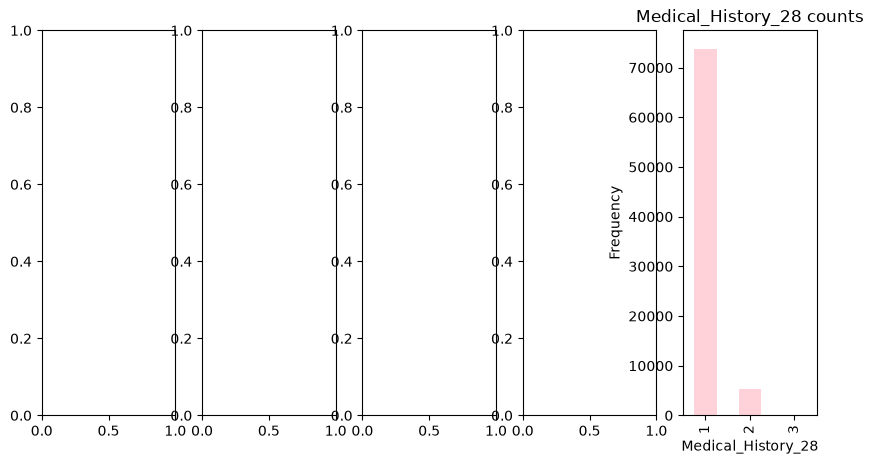

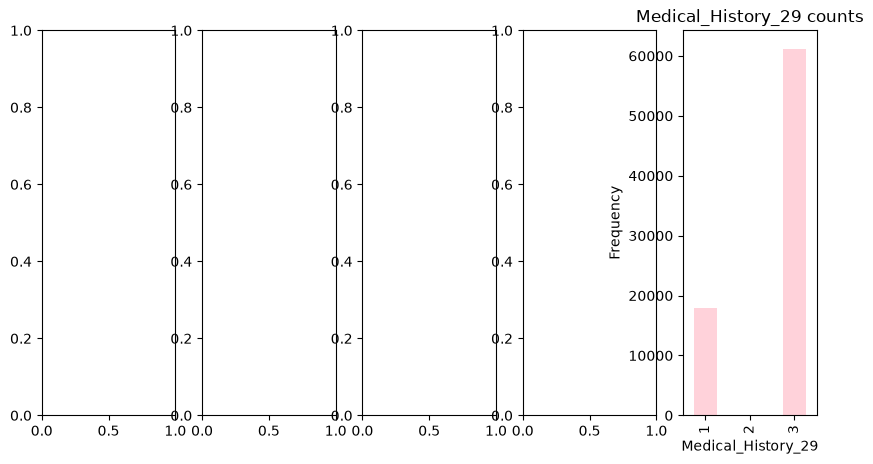

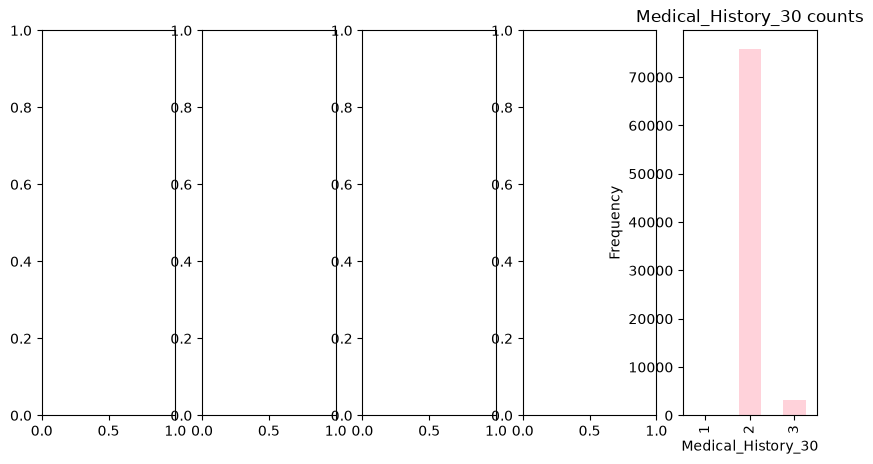

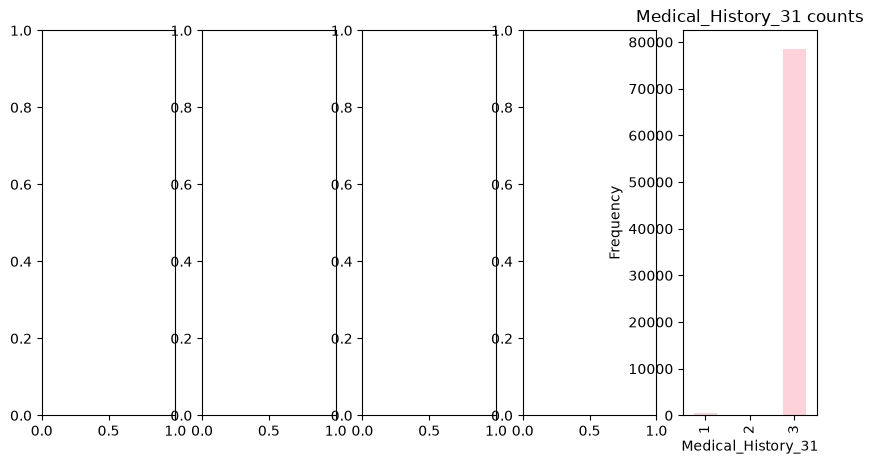

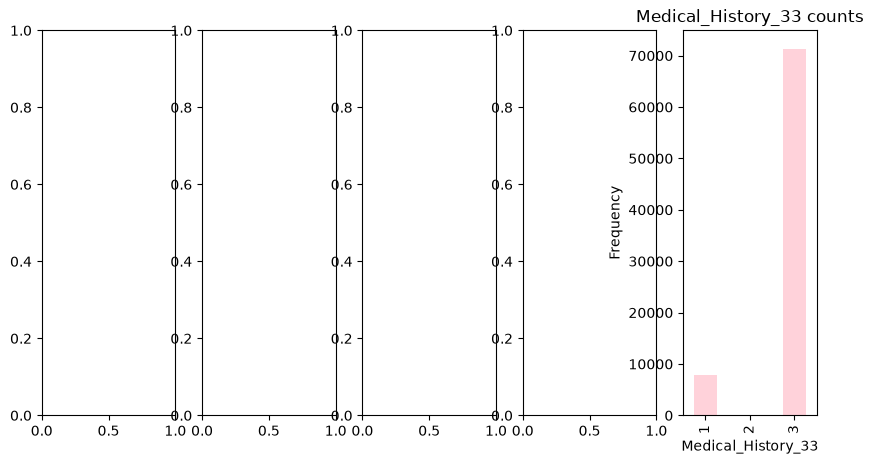

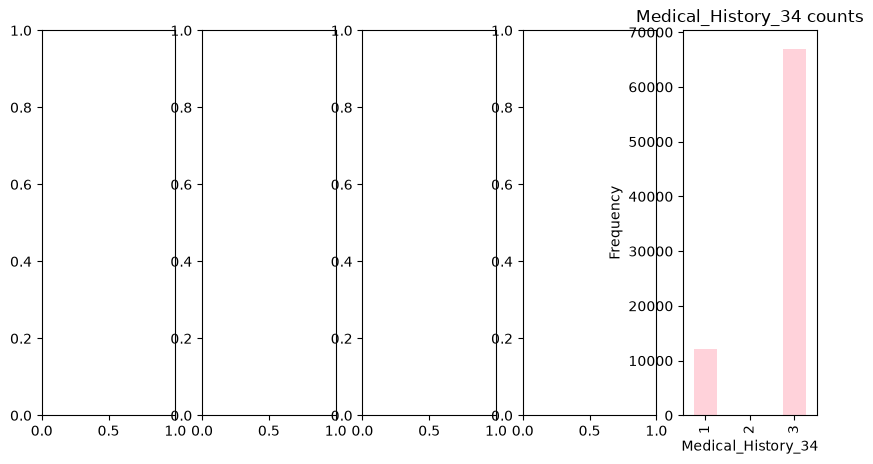

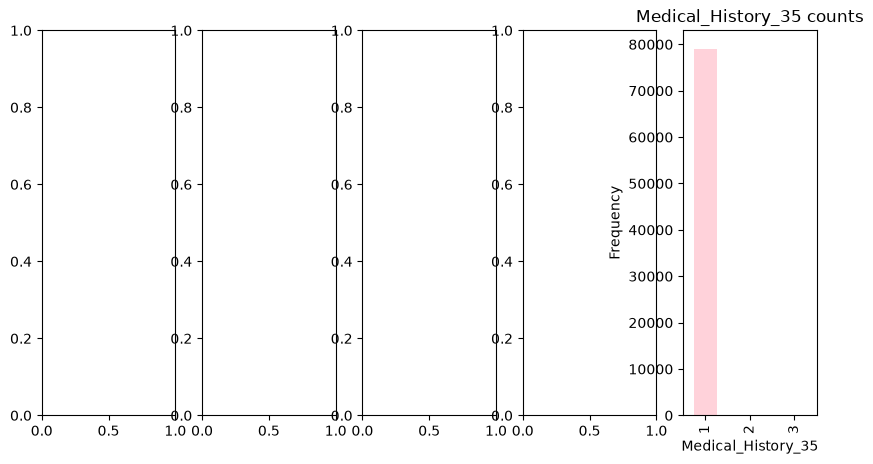

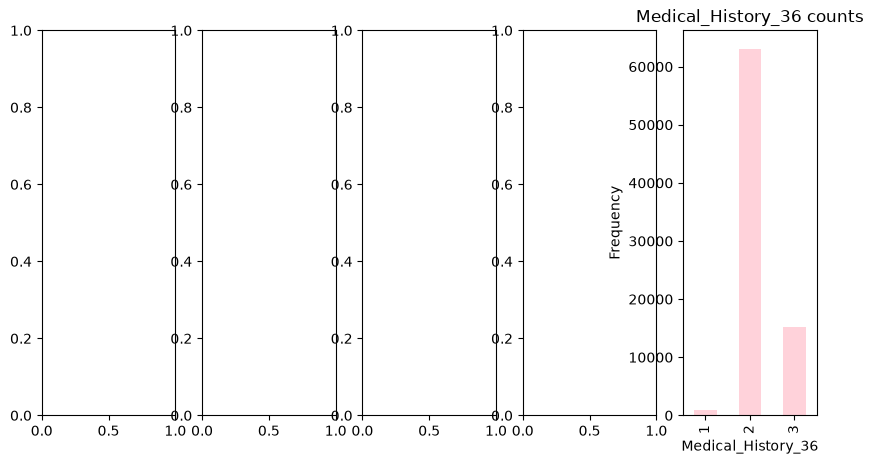

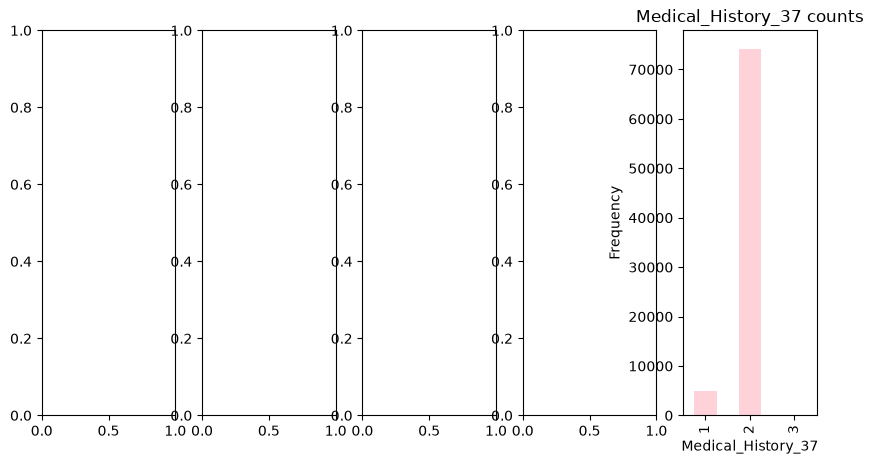

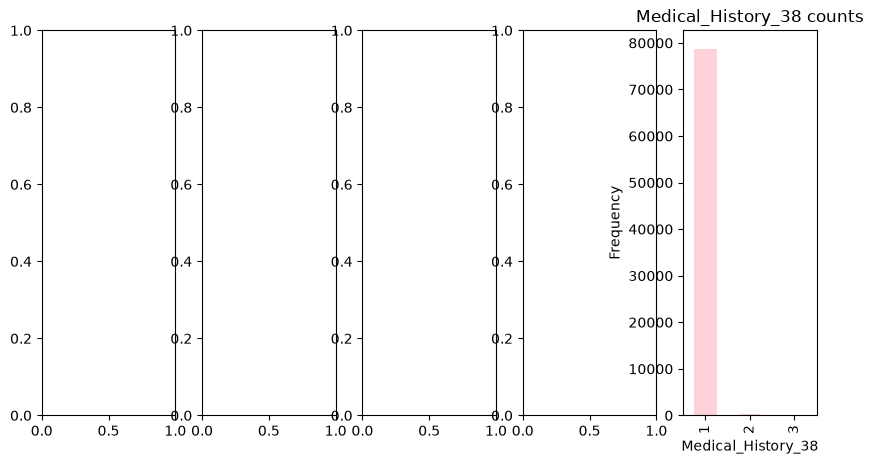

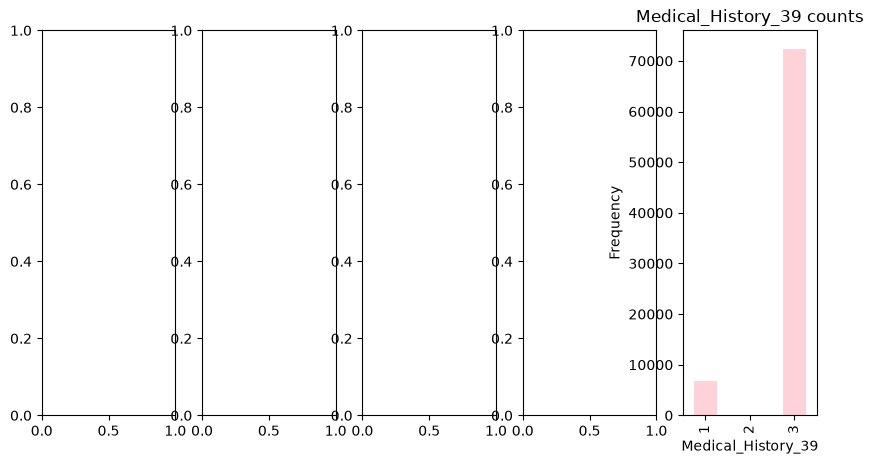

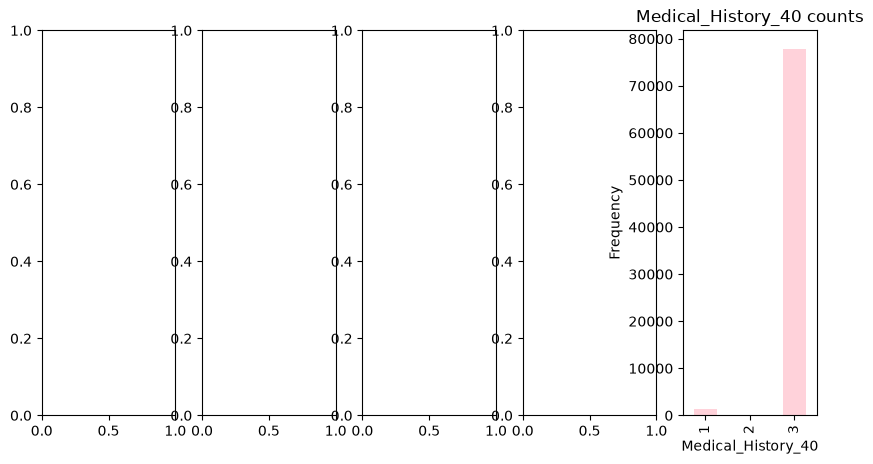

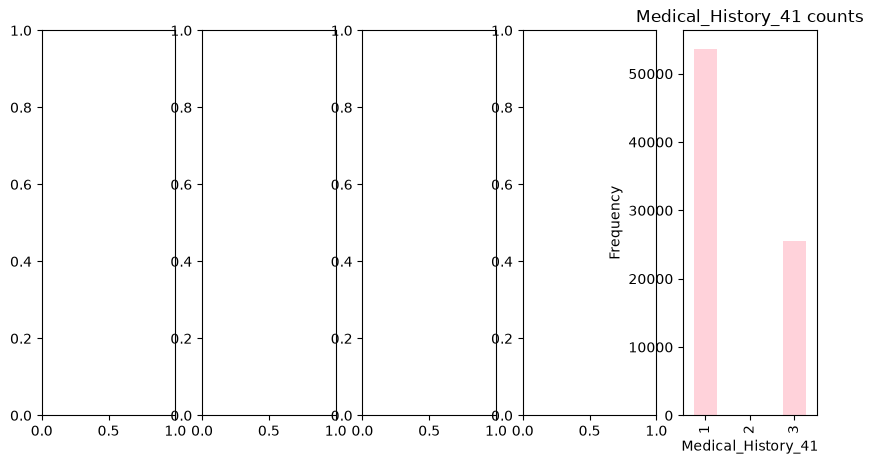

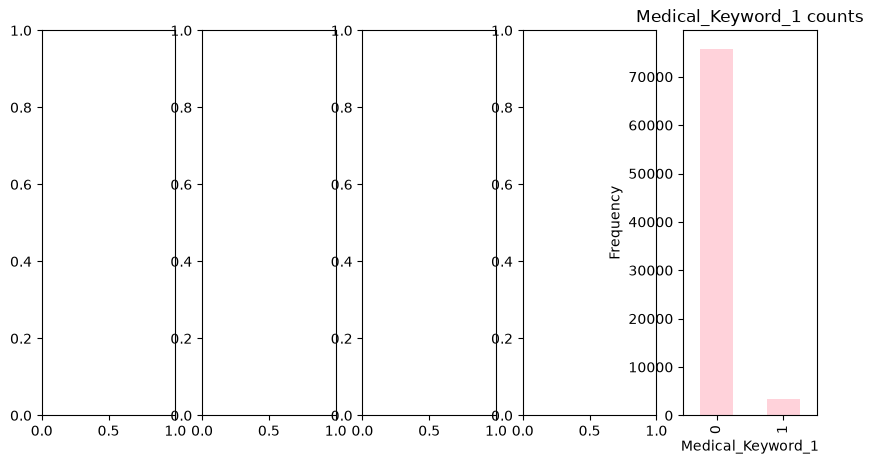

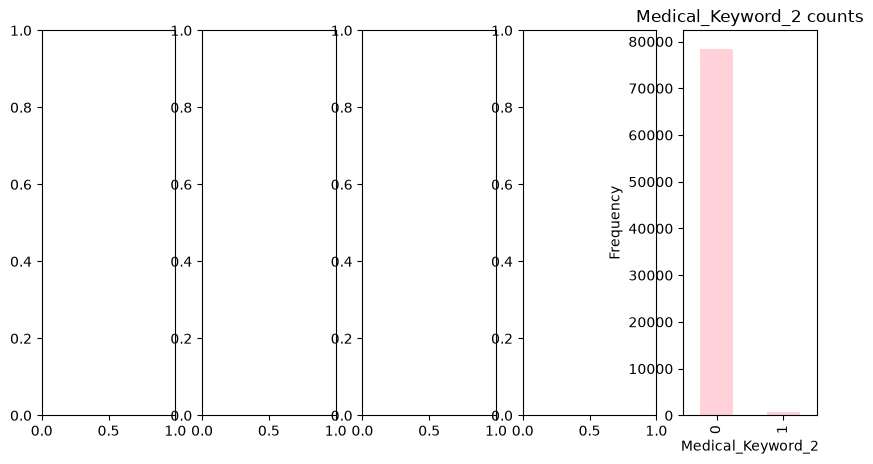

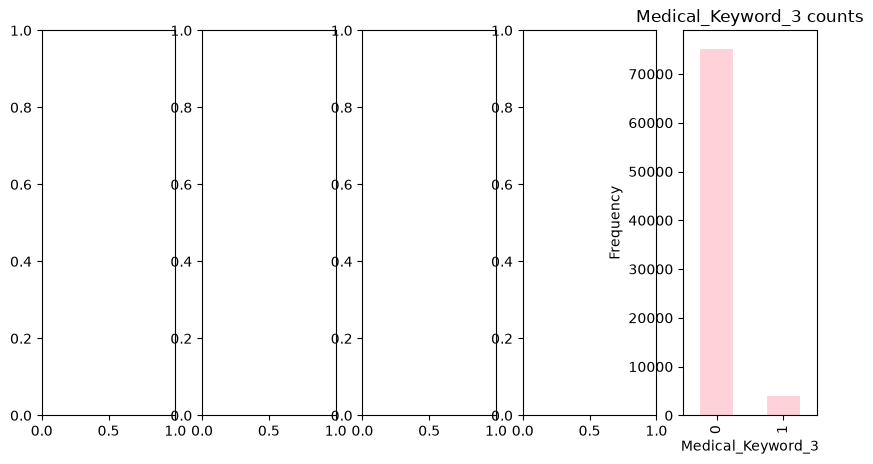

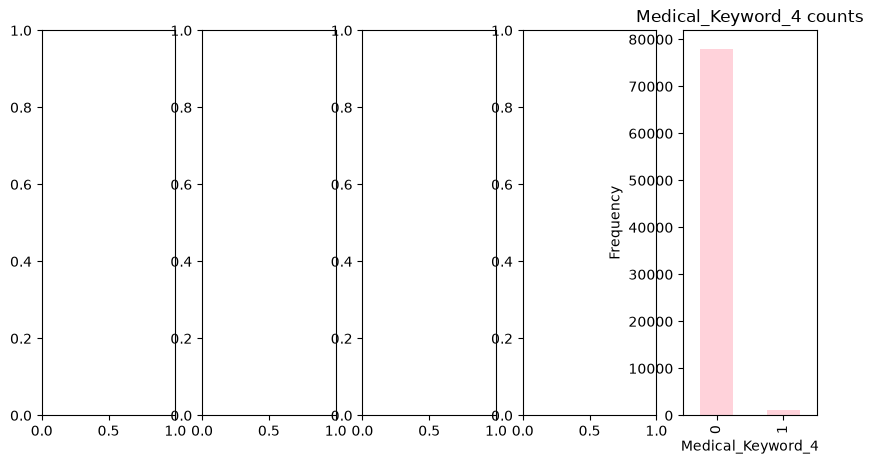

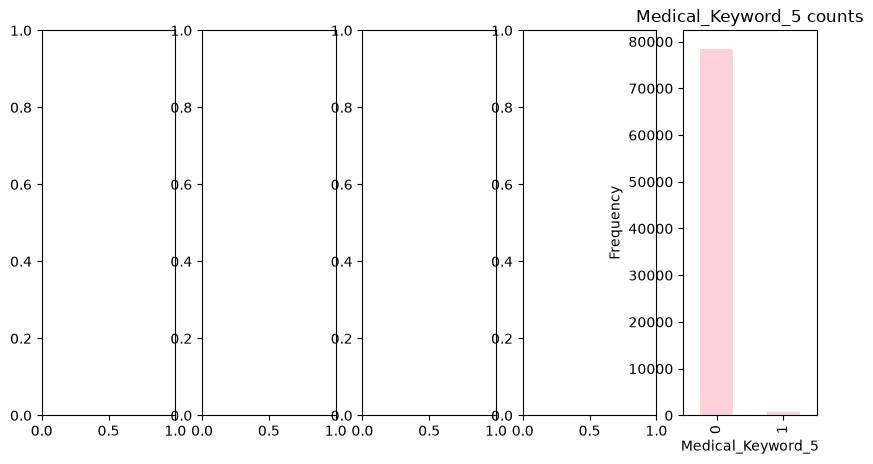

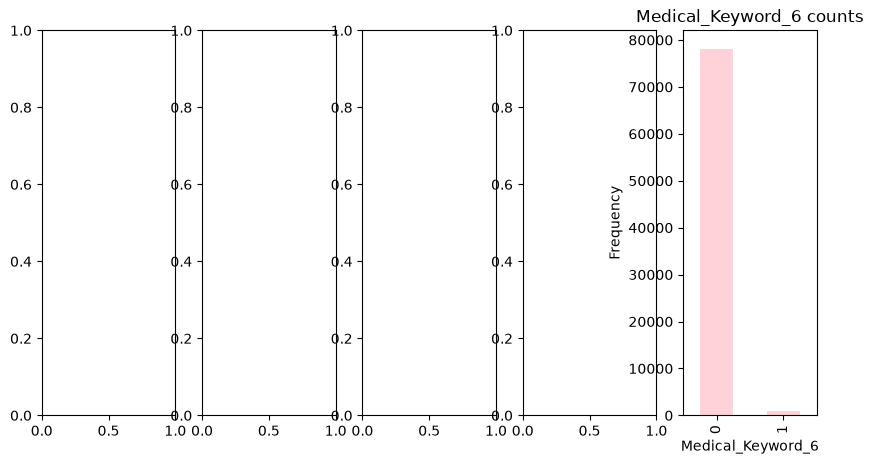

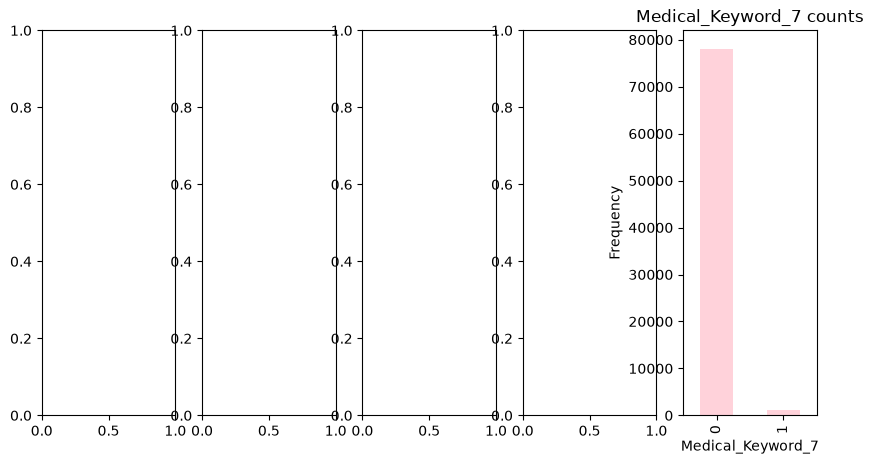

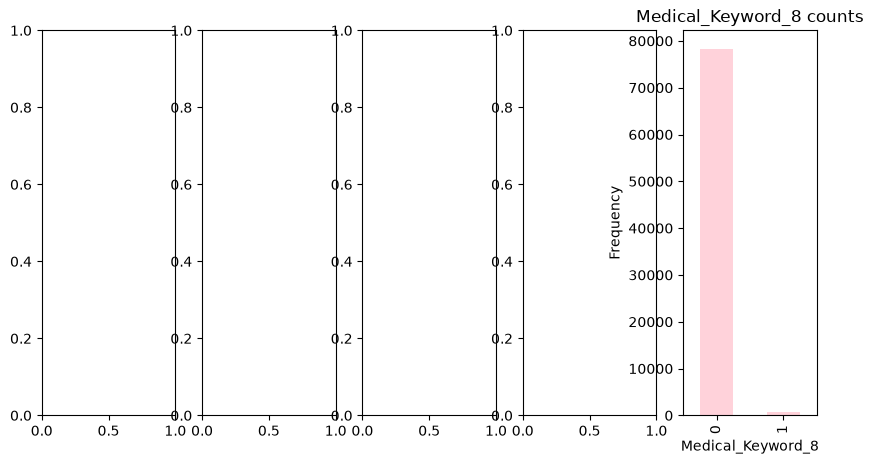

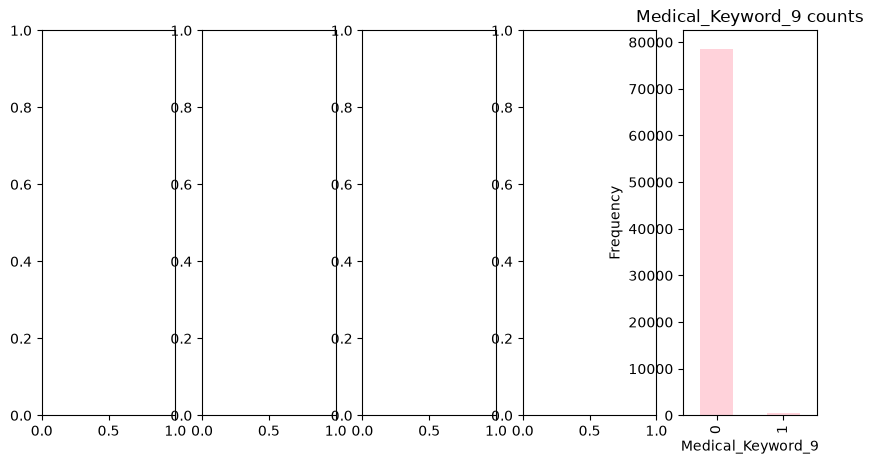

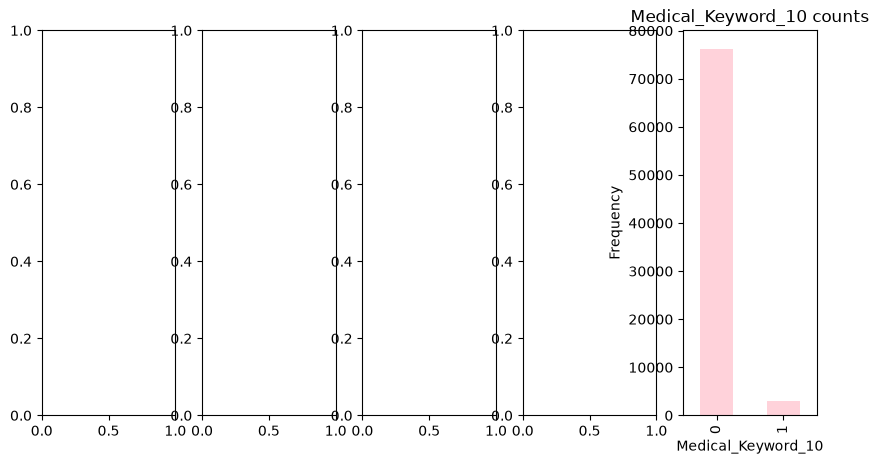

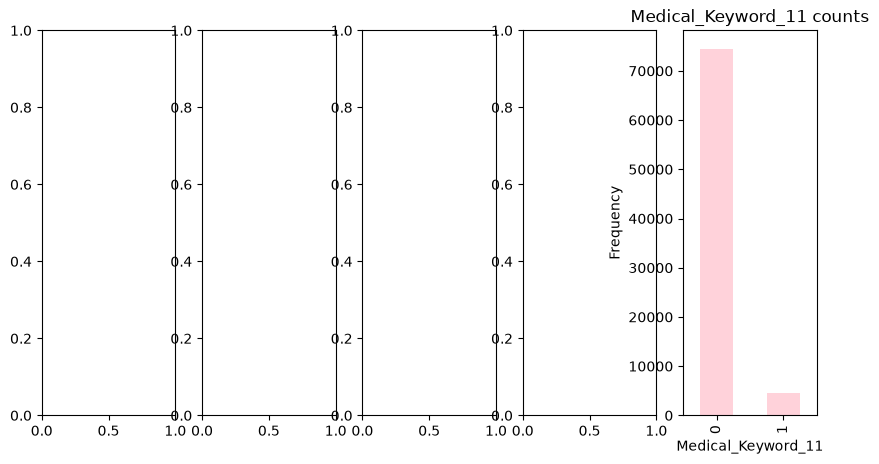

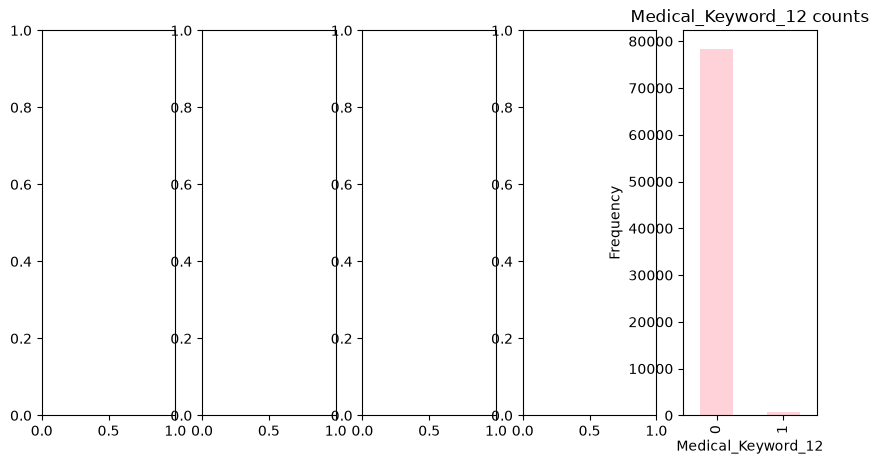

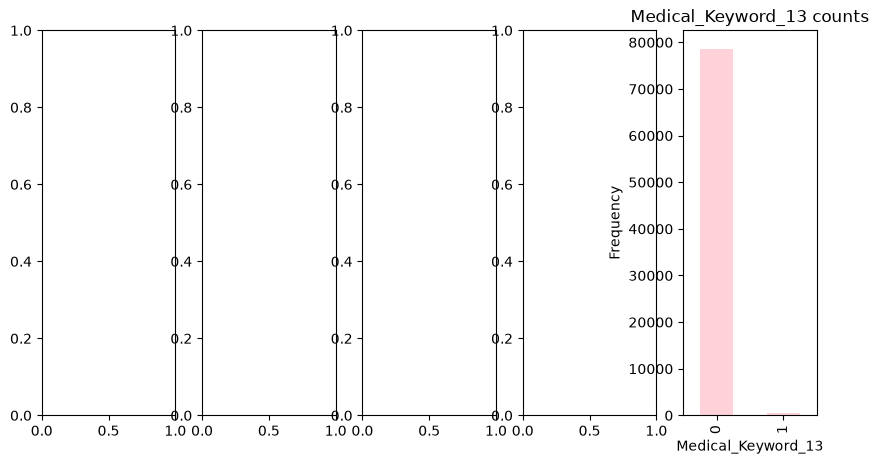

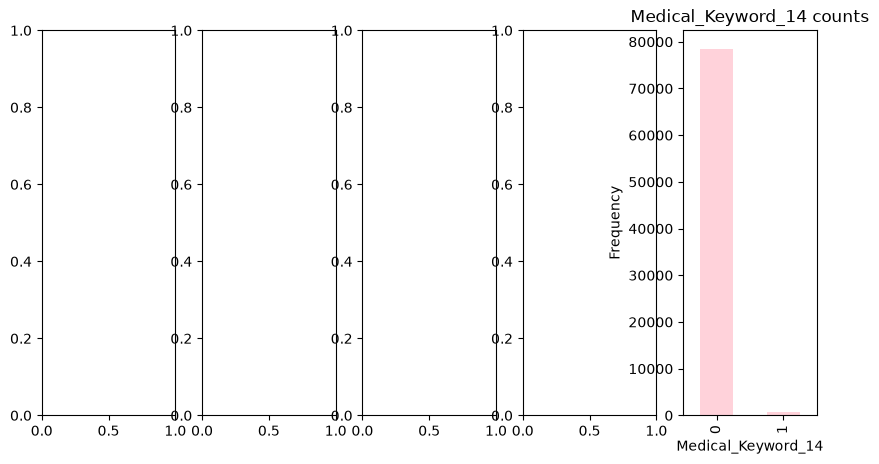

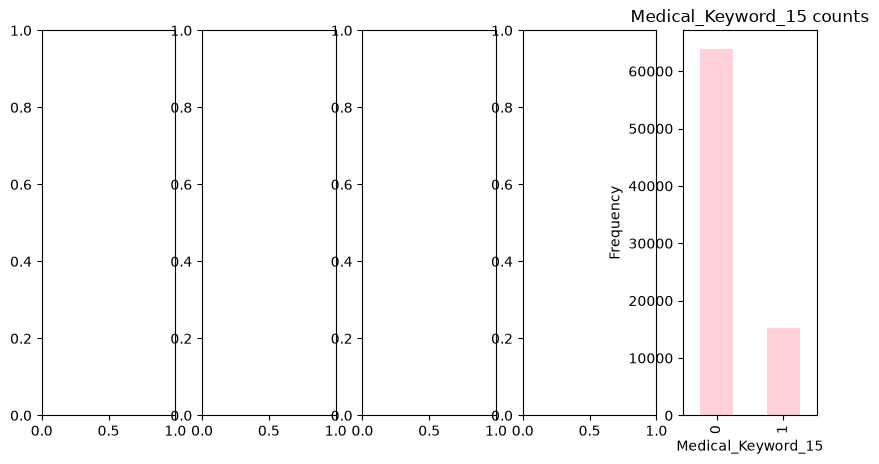

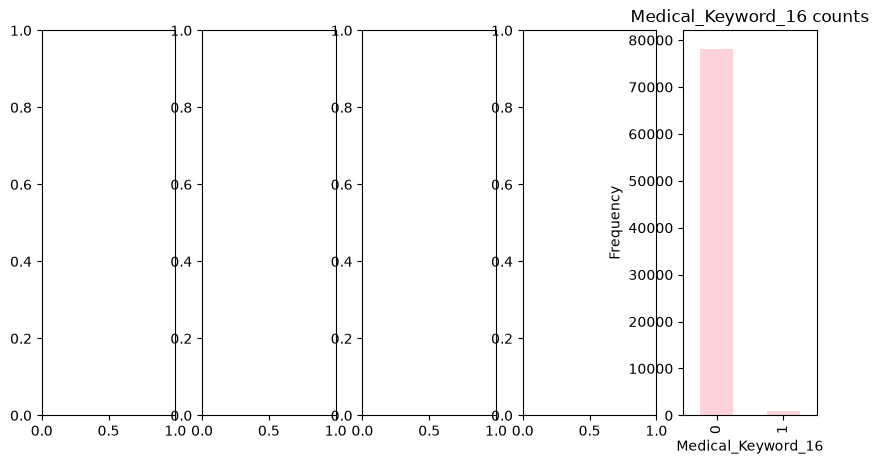

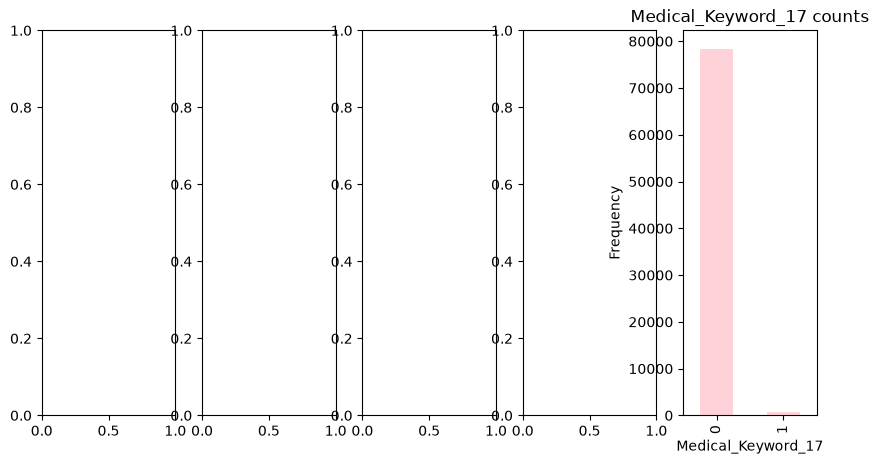

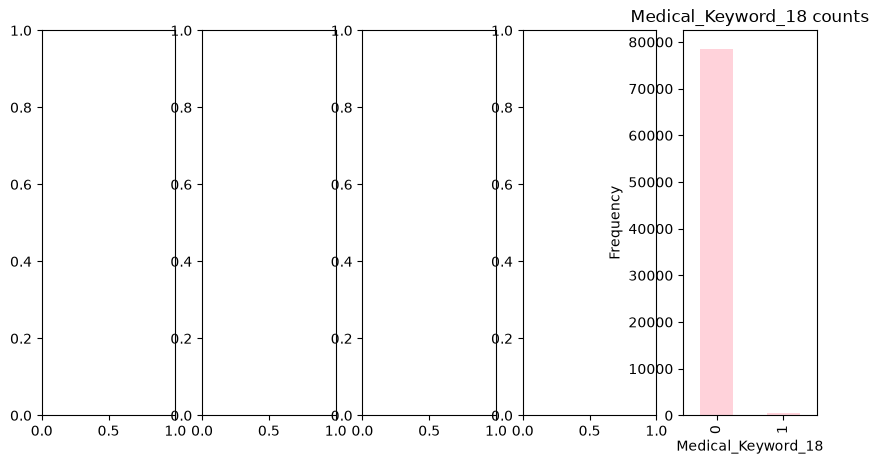

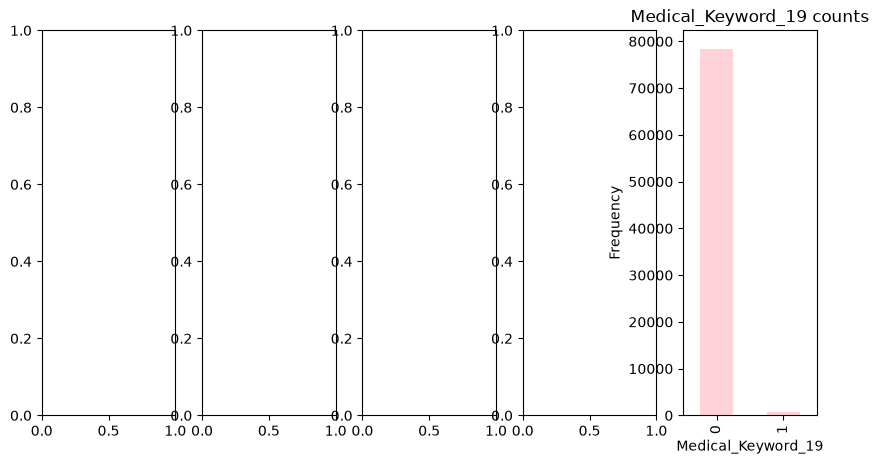

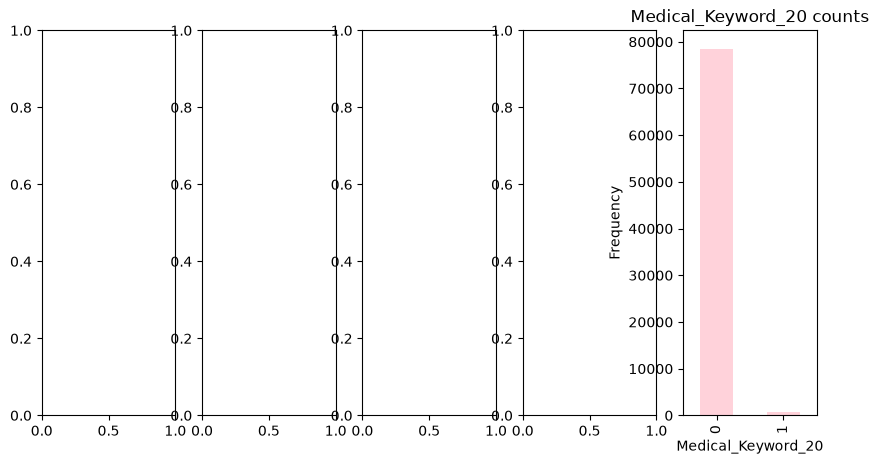

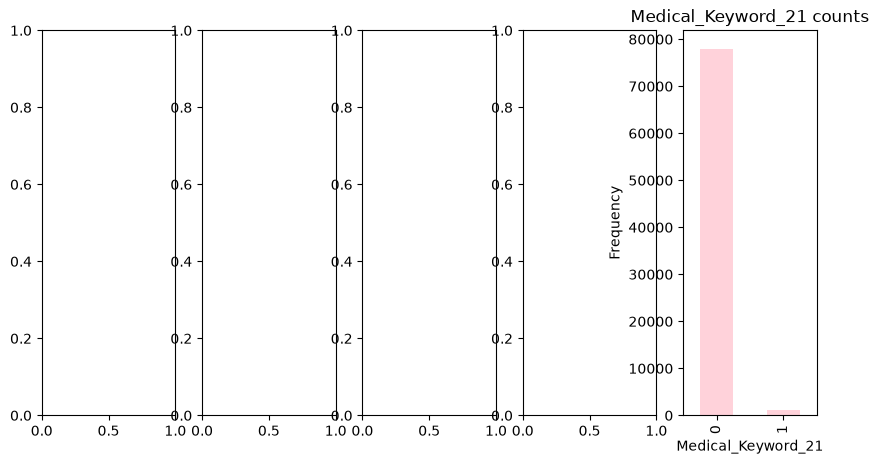

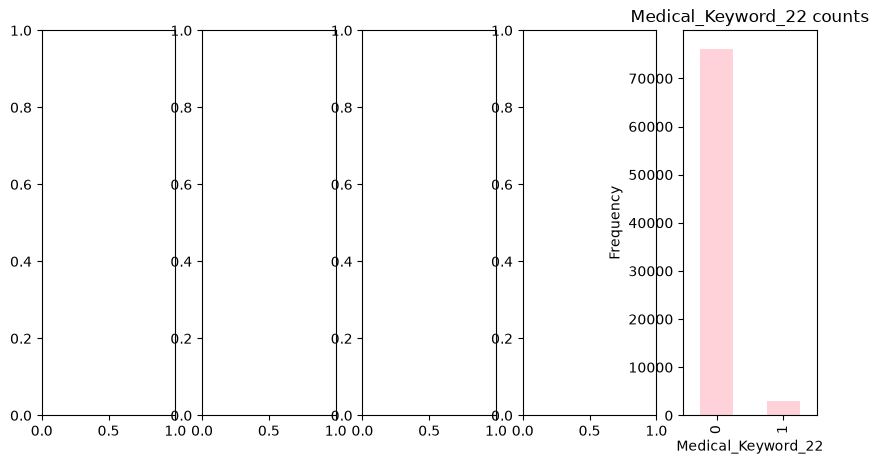

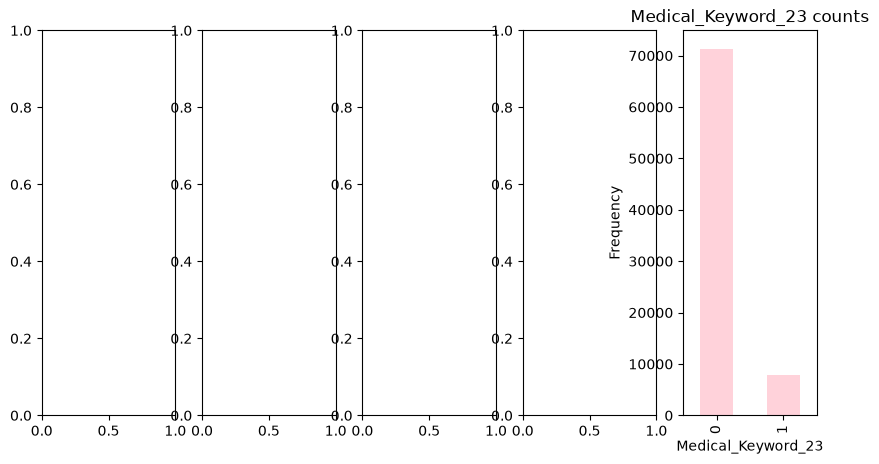

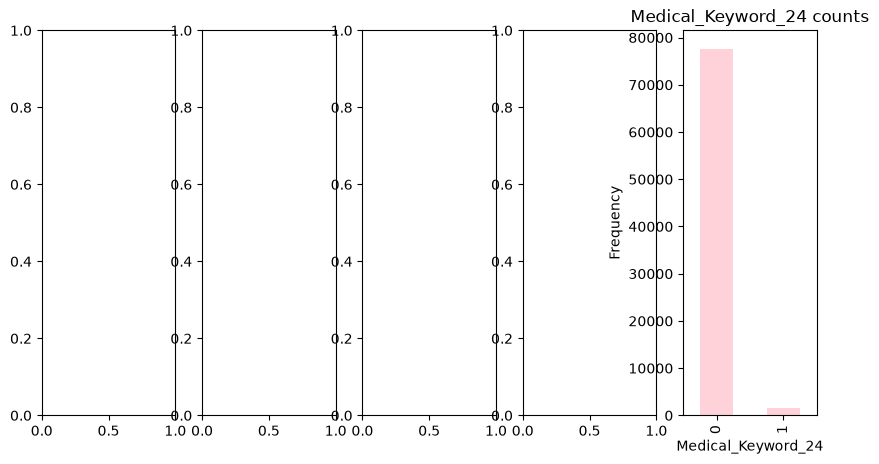

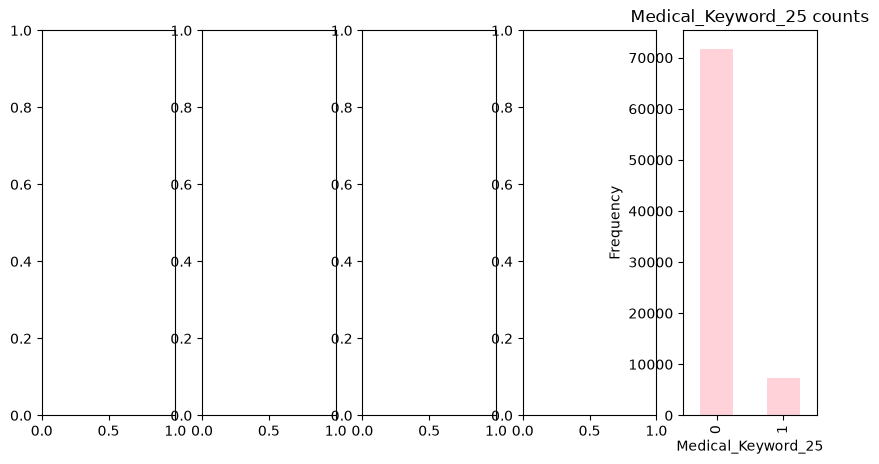

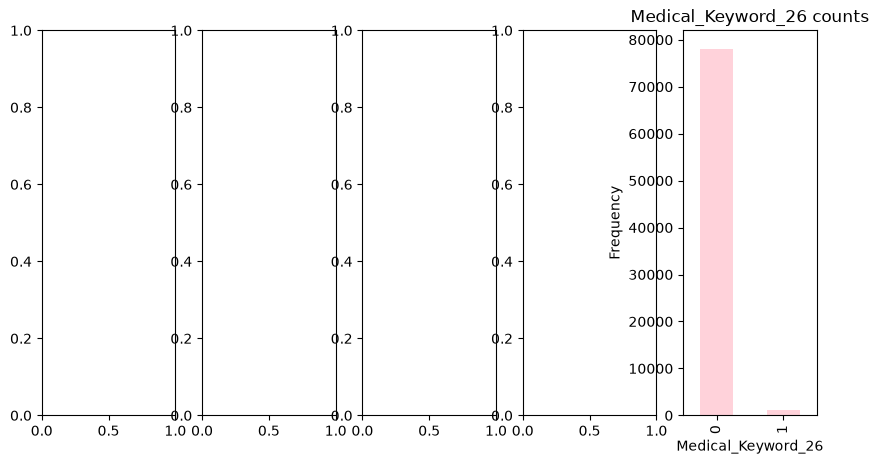

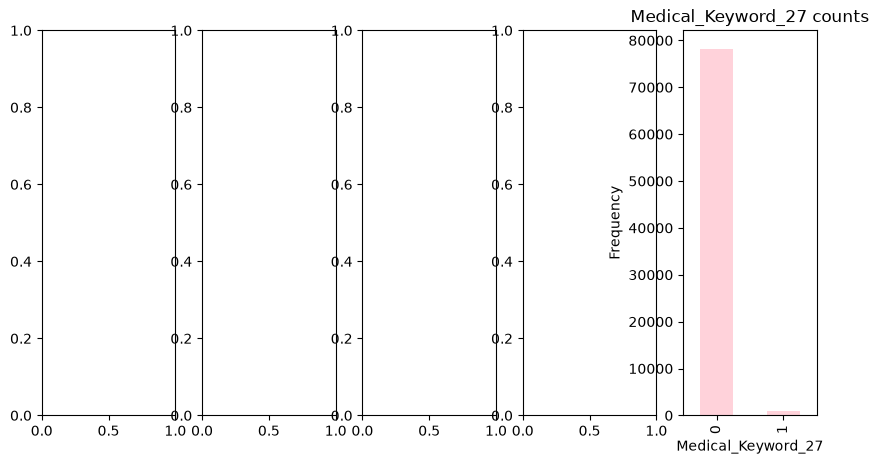

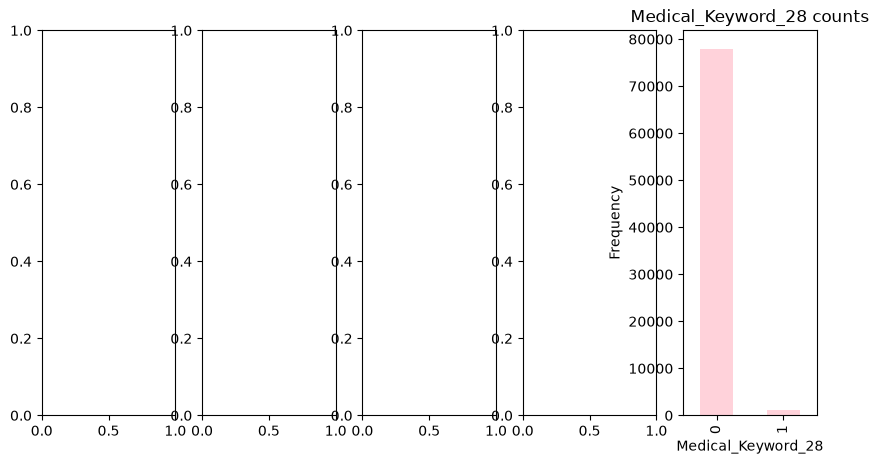

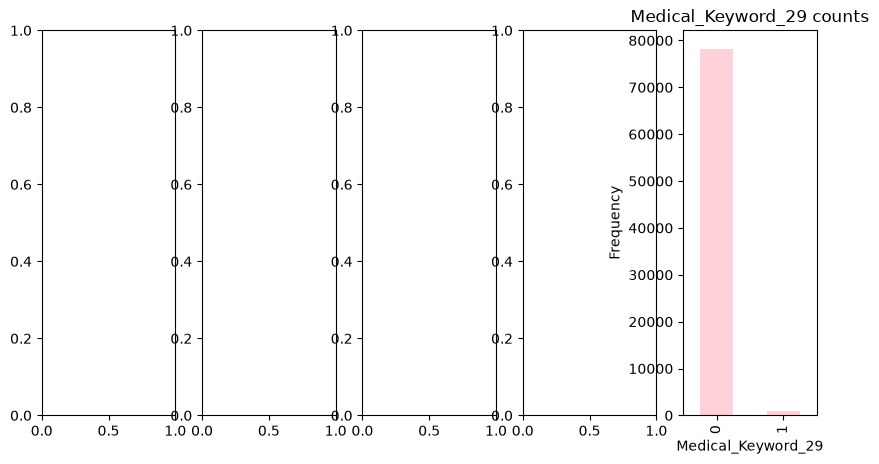

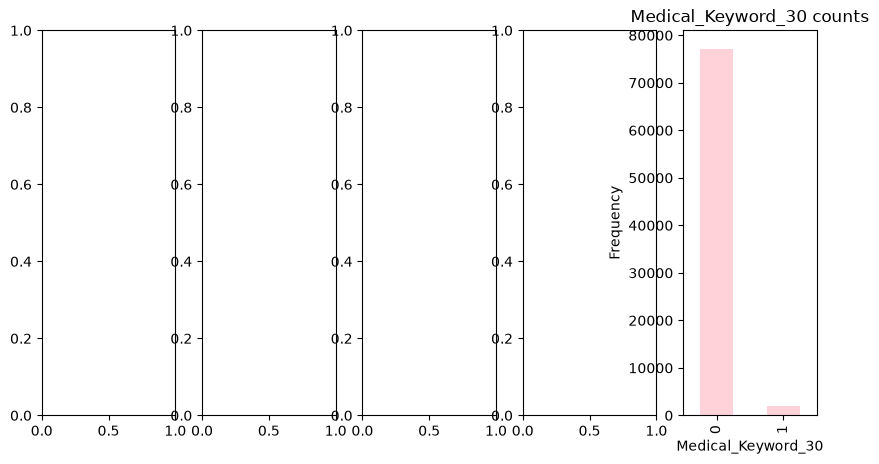

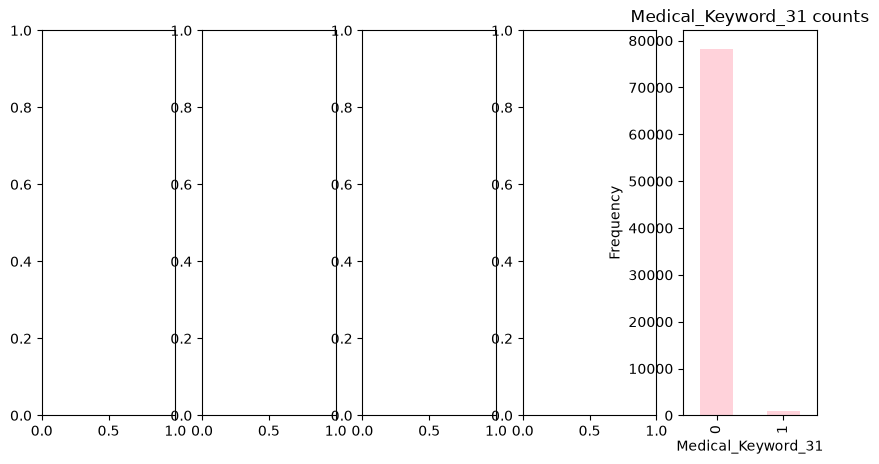

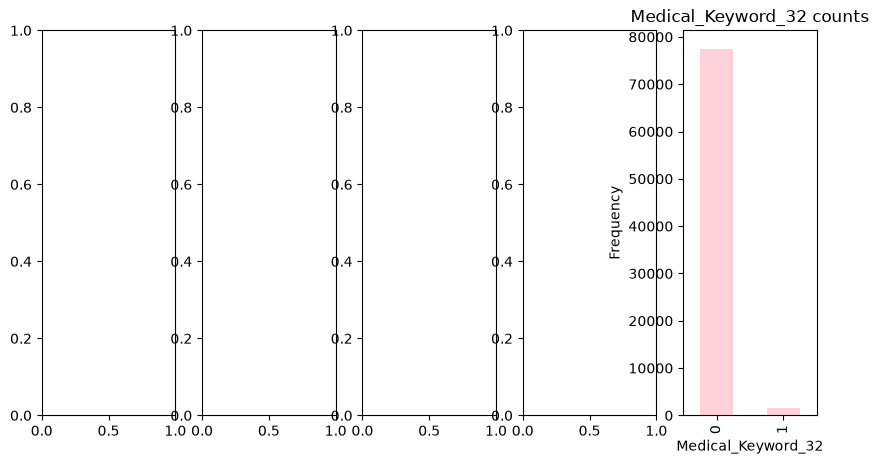

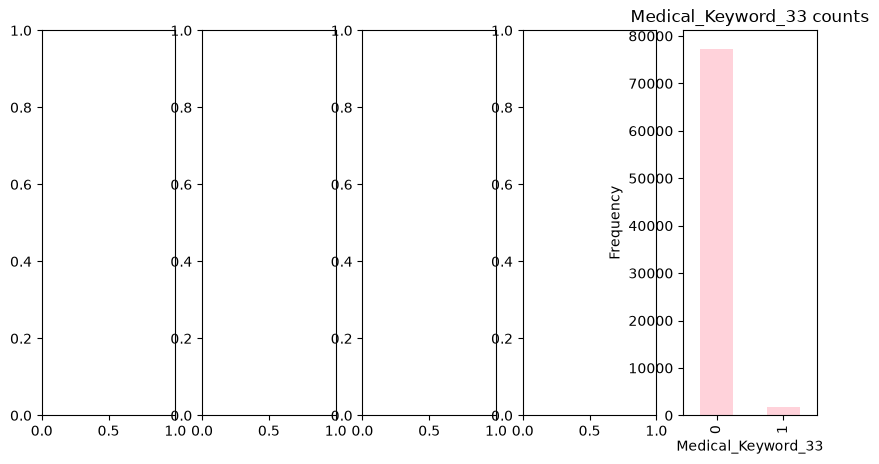

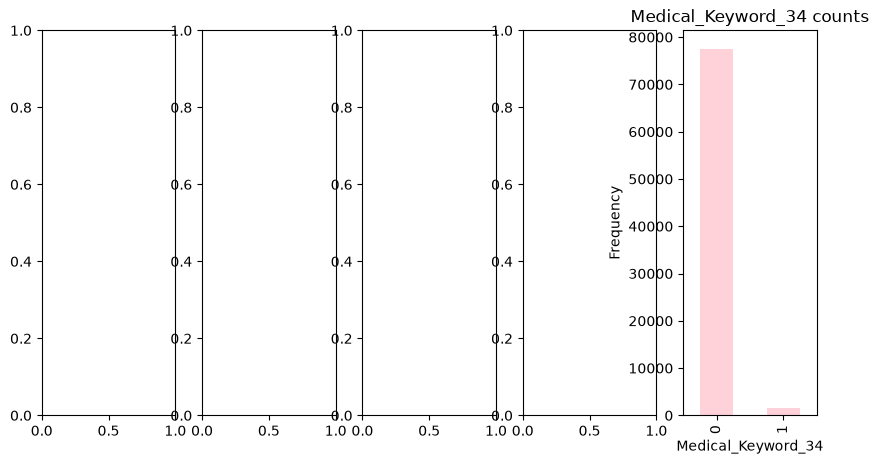

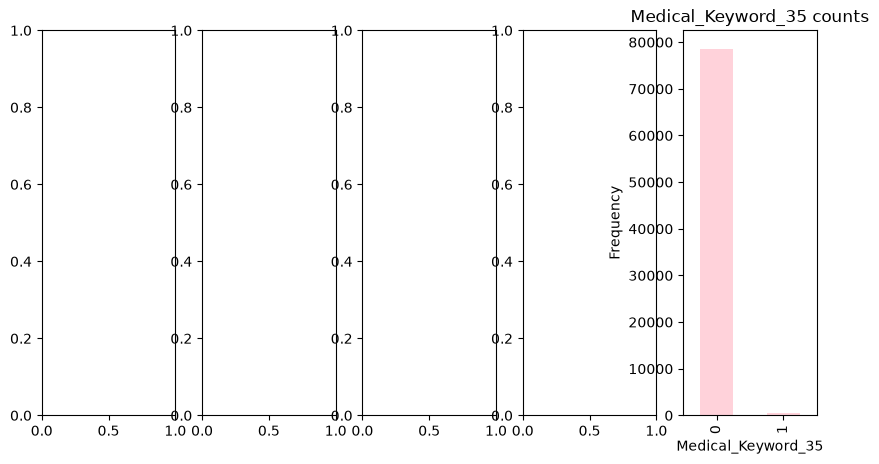

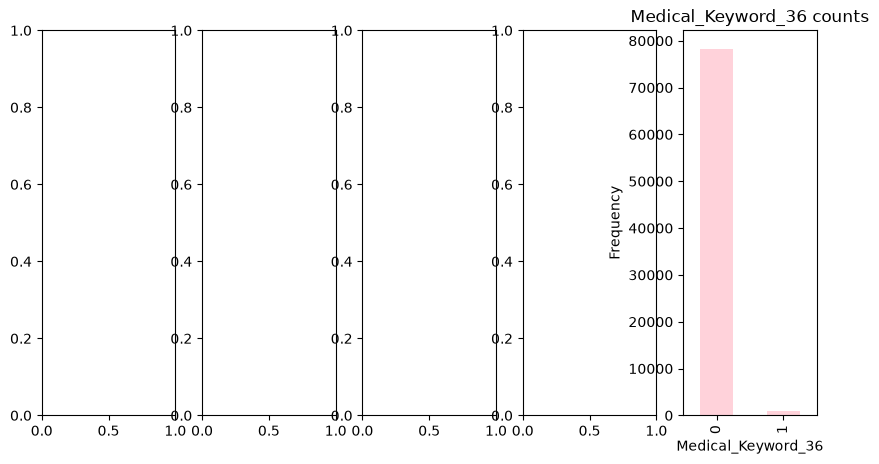

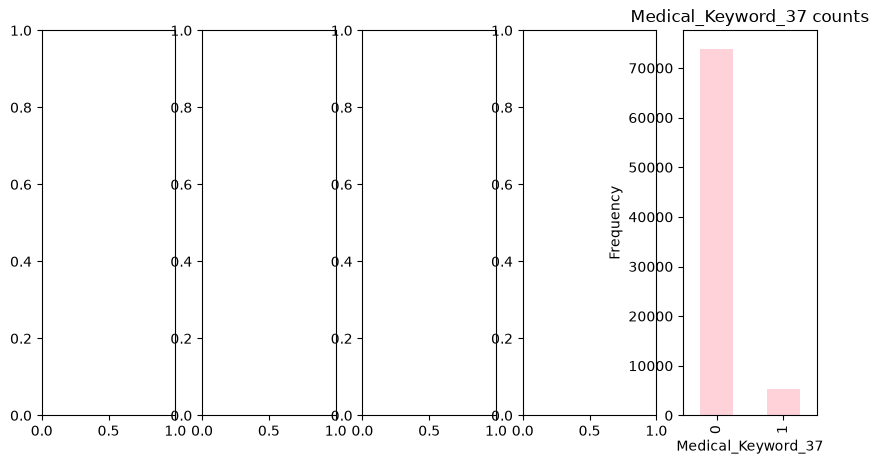

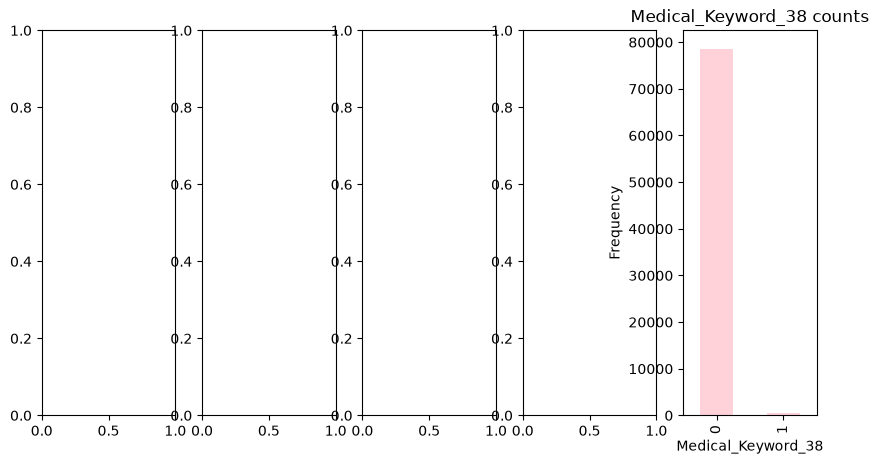

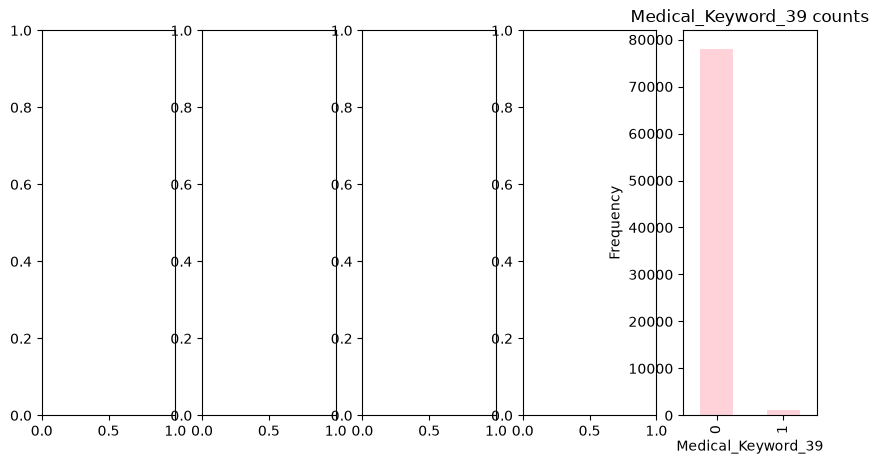

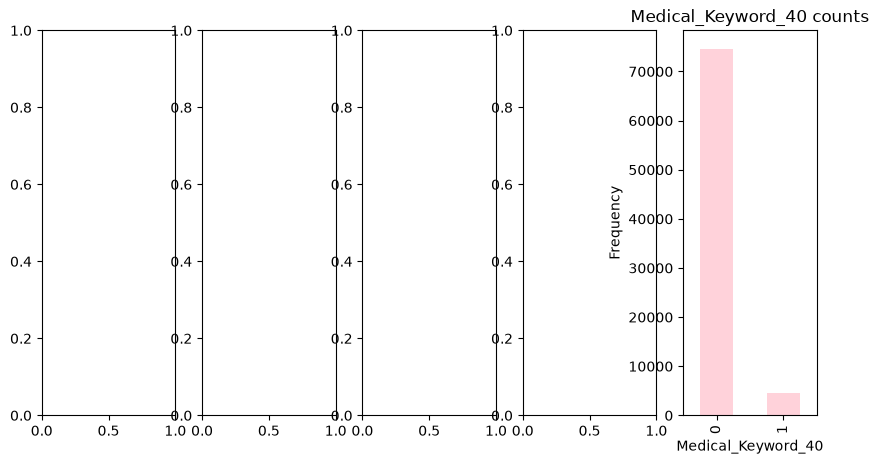

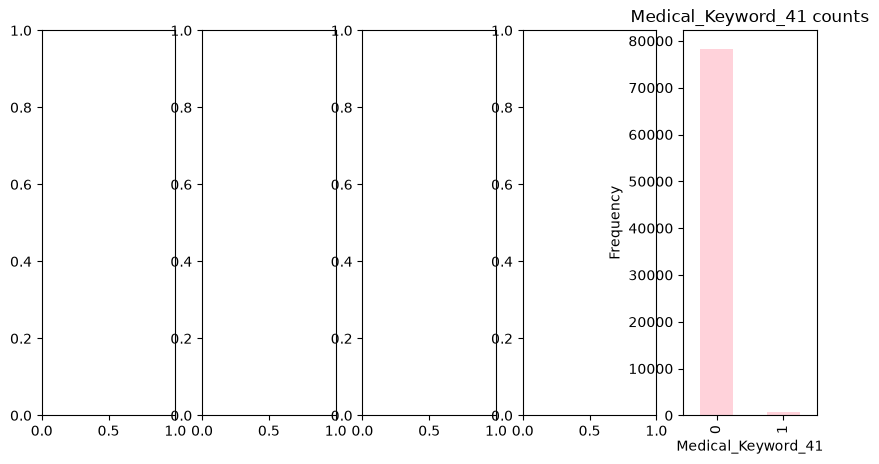

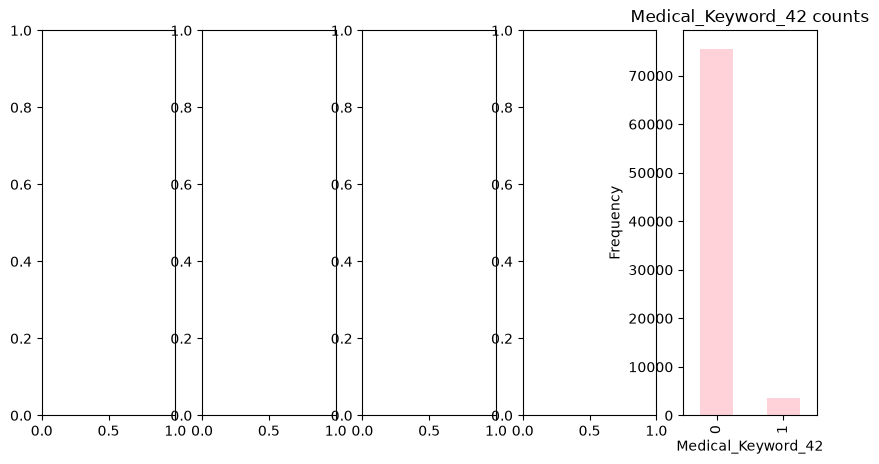

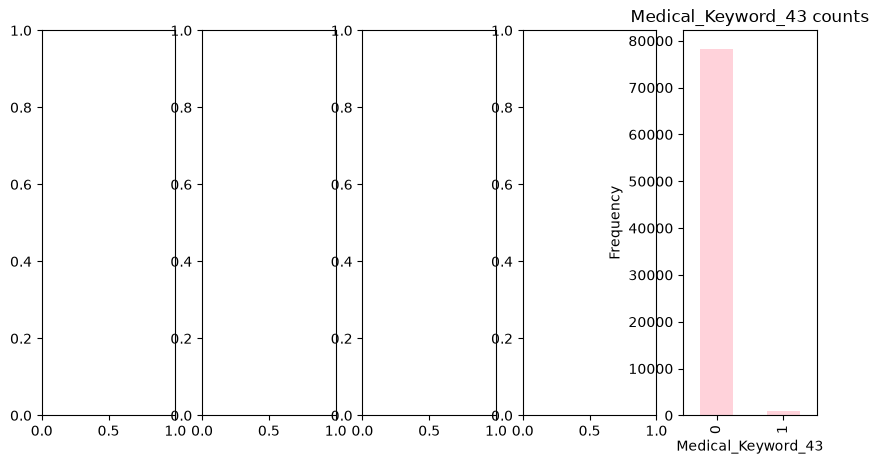

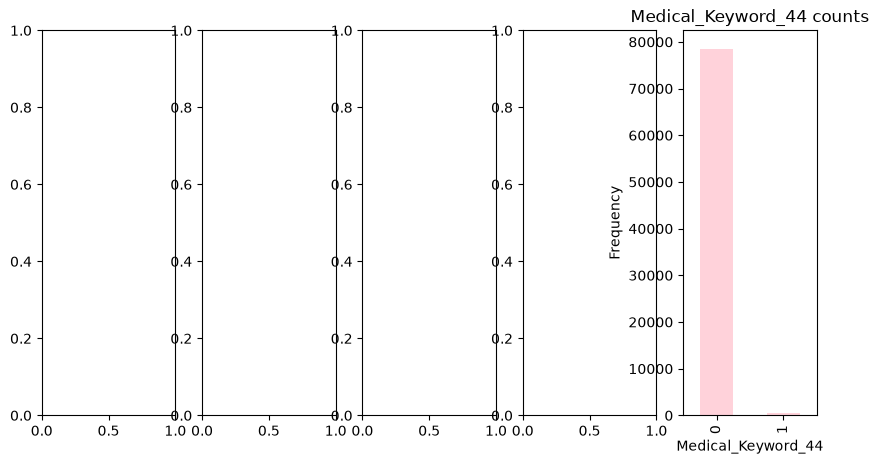

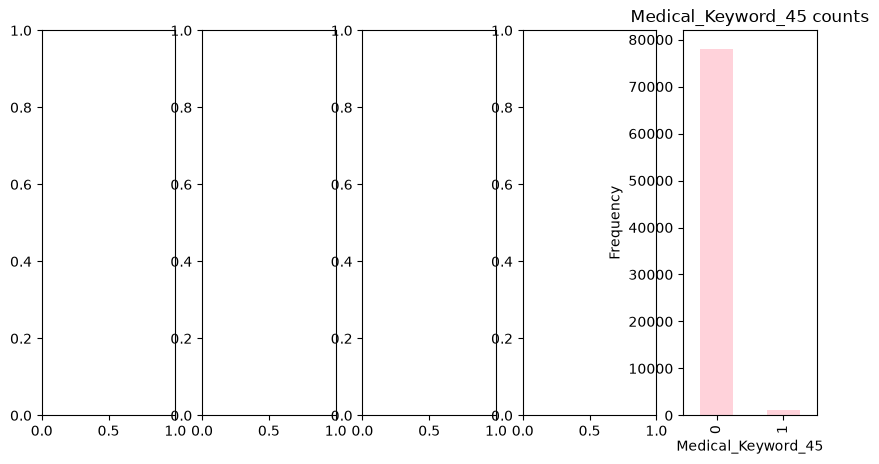

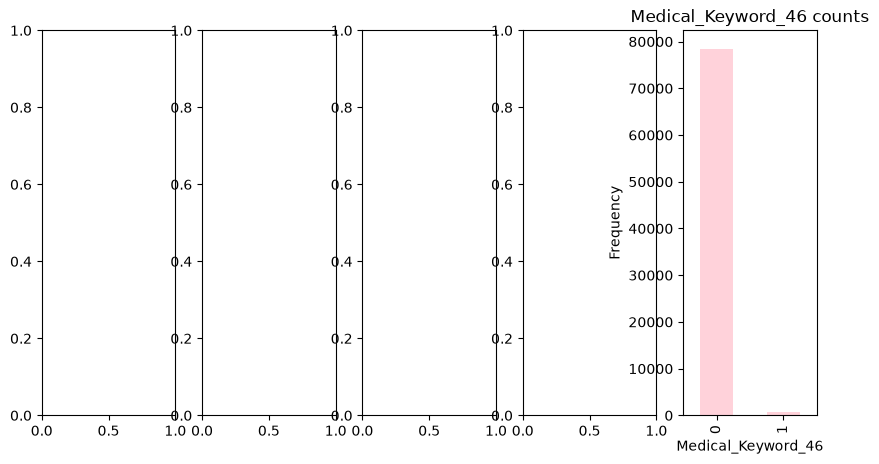

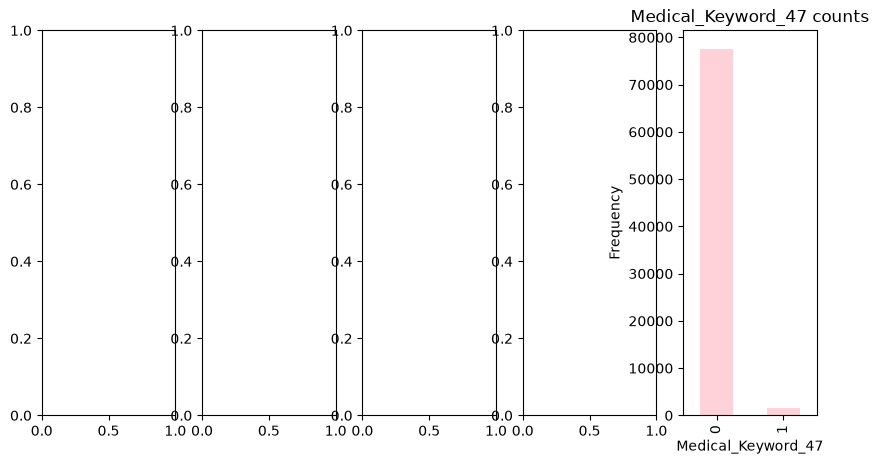

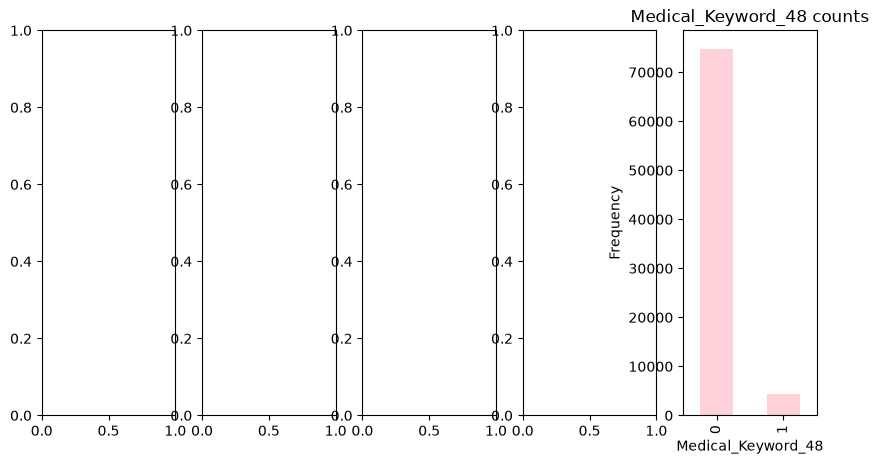

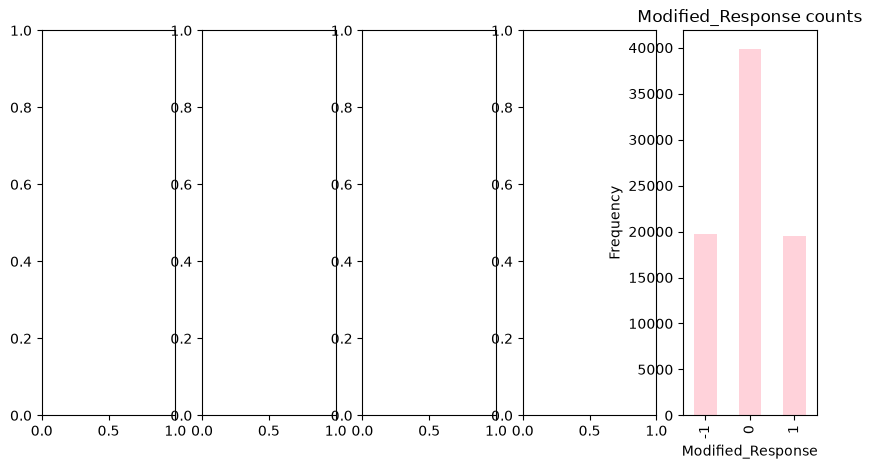

In [15]:
# Doing count plots for categorical
for col in categorical:
    counts = df[col].value_counts().sort_index()
    if len(counts) > 10 and len(counts) < 50 :
      fig = plt.figure(figsize=(50, 10))  
    elif len(counts) >50 :
      continue
    else:
      # fig = plt.figure(figsize=(3, 2))
      fig, axes = plt.subplots(1,5,figsize=(10, 5))
    ax = fig.gca()
    counts.plot.bar(ax = ax, color='pink', alpha=0.7)
    ax.set_title(col + ' counts')
    ax.set_xlabel(col) 
    ax.set_ylabel("Frequency")
plt.show()

> **D3 has the highest frequencies**

> Most of the features here are unbalanced.

<Axes: ylabel='Employment_Info_1'>

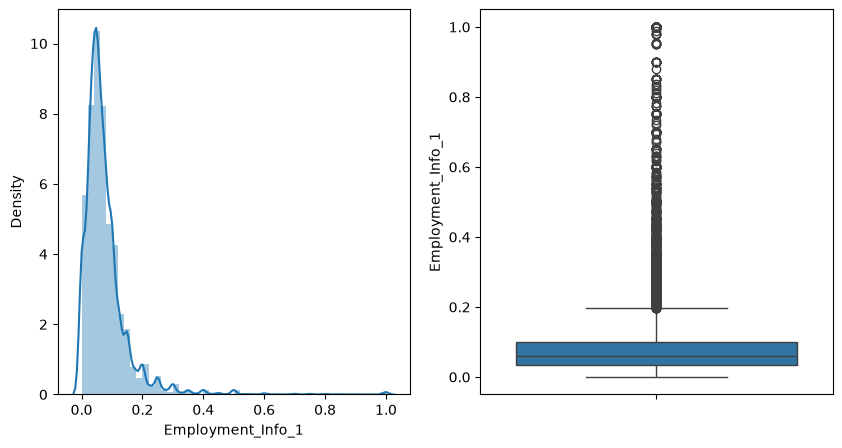

In [16]:
fig, axes = plt.subplots(1,2,figsize=(10,5))
sns.distplot(df['Employment_Info_1'], ax=axes[0])
sns.boxplot(df['Employment_Info_1'], ax=axes[1])

> Right skewed.

> Outliers can be seen.

<Axes: ylabel='Employment_Info_4'>

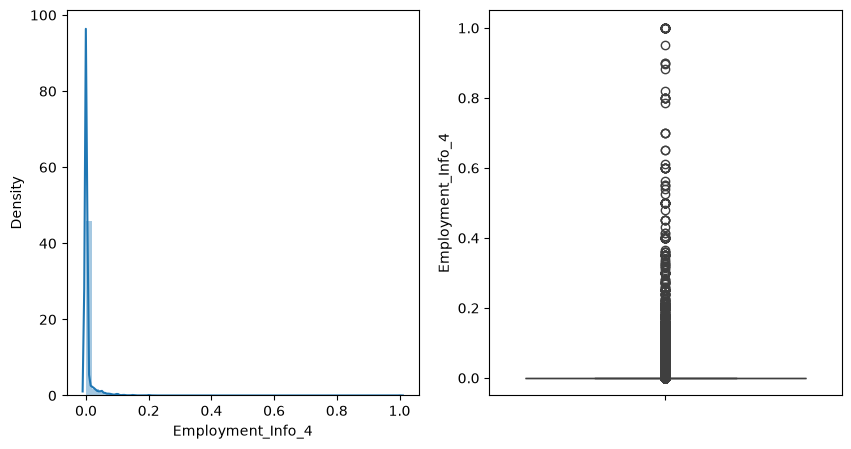

In [17]:
fig, axes = plt.subplots(1,2,figsize=(10,5))
sns.distplot(df['Employment_Info_4'], ax=axes[0])
sns.boxplot(df['Employment_Info_4'], ax=axes[1])

<Axes: ylabel='Employment_Info_6'>

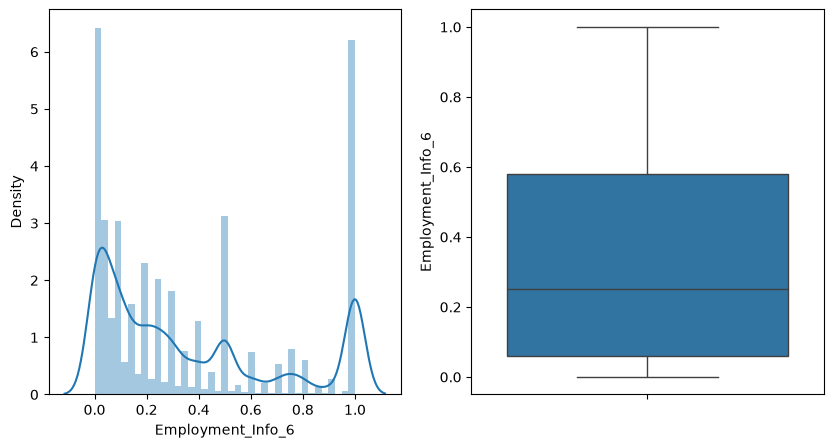

In [18]:
fig, axes = plt.subplots(1,2,figsize=(10,5))
sns.distplot(df['Employment_Info_6'], ax=axes[0])
sns.boxplot(df['Employment_Info_6'], ax=axes[1])

<Axes: ylabel='Family_Hist_4'>

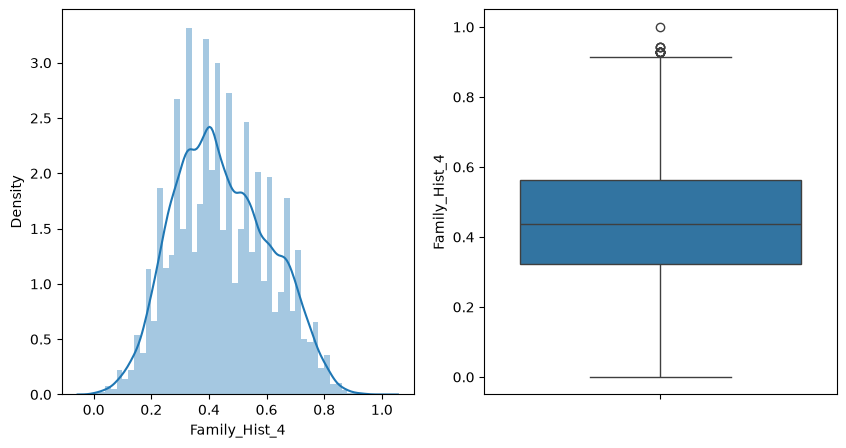

In [19]:
fig, axes = plt.subplots(1,2,figsize=(10,5))
sns.distplot(df['Family_Hist_4'], ax=axes[0])
sns.boxplot(df['Family_Hist_4'], ax=axes[1])

### **Checking Correlation For Features greater than 0.8**

In [20]:
# I just checked correlated feature with greater than 0.8 here
corr = df.drop(columns=['Modified_Response']).select_dtypes(include=[np.number]).corr()
corr_greater_than_80 = corr[corr >= 0.8]
corr_greater_than_80
corr_greater_than_80 = corr[corr>=.8]
corr_greater_than_80


,Id,Product_Info_1,Product_Info_3,Product_Info_4,Product_Info_5,Product_Info_6,Product_Info_7,Ins_Age,Ht,Wt,...,Medical_Keyword_39,Medical_Keyword_40,Medical_Keyword_41,Medical_Keyword_42,Medical_Keyword_43,Medical_Keyword_44,Medical_Keyword_45,Medical_Keyword_46,Medical_Keyword_47,Medical_Keyword_48
Id,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_Info_1,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_Info_3,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_Info_4,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_Info_5,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Medical_Keyword_44,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN
Medical_Keyword_45,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN
Medical_Keyword_46,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN
Medical_Keyword_47,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN


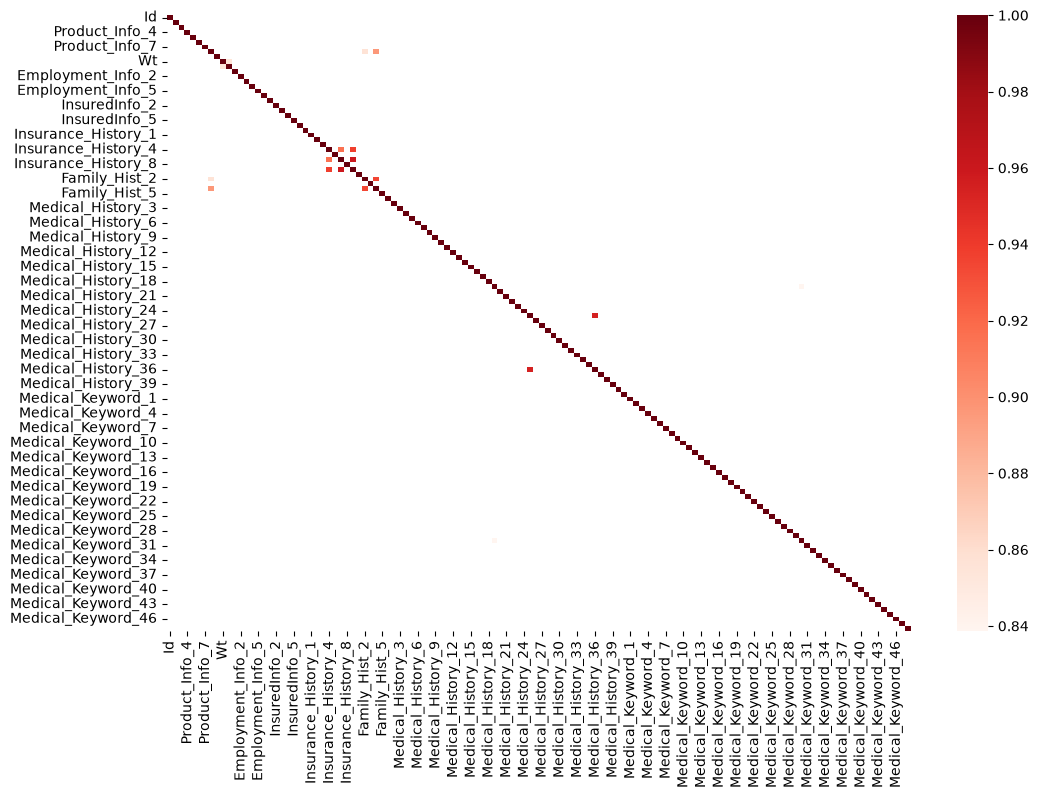

In [21]:
plt.figure(figsize=(12,8))
sns.heatmap(corr_greater_than_80, cmap="Reds");

### **CONCLUSION**

> BMI and Weight are highly correlated, which makes sense also as these 2 features are directly proprtional.

> Ins_Age and Family_Hist_4, Family_Hist_2 highly correlated

> Although, I am not going to perform any transformation on any feature or drop any as these are tree based models and they don't get affected by correlation much because of their non parametric nature.

In [22]:
#setting max columns to 200
pd.set_option('display.max_columns', 200)
pd.set_option('display.max_rows', 200)

### **Null Value Check**

In [23]:
#checking percentage of missing values in a column
missing_val_count_by_column = df.isnull().sum()/len(df)

print(missing_val_count_by_column[missing_val_count_by_column > 0.4].sort_values(ascending=False))

Medical_History_10     0.990423
Medical_History_32     0.981578
Medical_History_24     0.937066
Medical_History_15     0.751270
Family_Hist_5          0.700414
Family_Hist_3          0.572423
Family_Hist_2          0.486898
Insurance_History_5    0.423281
dtype: float64


### **Removing unimportant column**

In [ ]:
# Dropping all columns in which greater than 40 percent null values
df = df.dropna(axis=1, thresh=int(df.shape[0] * 0.6))

In [25]:
# Does not contain important information
df.drop('Product_Info_2',axis=1,inplace=True)

### **X and Y split**

In [26]:
# Data for all the independent variables
X = df.drop(labels='Modified_Response',axis=1)

# Data for the dependent variable
Y = df['Modified_Response']

### **Filling Remaining Missing Values**

In [27]:
# Filling remaining missing values with mean
X = X.fillna(X.mean())

### **Train Test Split**

In [28]:
# Train-test split

X_train, X_test, Y_train, Y_test = train_test_split(X,Y,test_size = 0.25, random_state=1)

### **Shapes of Train and Test Data**

In [29]:
# Check the shape of train dataset
print(X_train.shape,Y_train.shape)

# Check the shape of test dataset
print(X_test.shape, Y_test.shape)


print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

(59359, 118) (59359,)
(19787, 118) (19787,)
Training samples: 59359
Testing samples: 19787


## Hyperparameter tuning and model training

In [31]:
RANDOM_STATE = 41

# 1. Safely encode target labels to [0, 1, ..., n_classes - 1]
le = LabelEncoder()
Y_train_adj = le.fit_transform(Y_train)
num_classes = len(le.classes_)
print(f"Detected {num_classes} target classes: {le.classes_} -> encoded as {np.unique(Y_train_adj)}")

# 2. Cross-Validation Setup
cv_splits = min(5, int(pd.Series(Y_train_adj).value_counts().min()))
if cv_splits < 2:
    raise ValueError("Not enough training examples per class for cross-validation.")
cv = StratifiedKFold(n_splits=cv_splits, shuffle=True, random_state=RANDOM_STATE)

# 3. Custom Multi-Metric Scoring (QWK is standard for Prudential dataset)
qwk_scorer = make_scorer(cohen_kappa_score, weights="quadratic")
scoring_metrics = {
    "QWK": qwk_scorer,
    "F1_Weighted": "f1_weighted"
}

# 4. Models and Hyperparameter Grids
models_and_grids = {
    "Logistic Regression": (
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE))
        ]),
        {
            "model__C": [0.01, 0.1, 1, 10]
        }
    ),
    "Linear SVM": (
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", LinearSVC(class_weight="balanced", dual="auto", max_iter=3000, random_state=RANDOM_STATE))
        ]),
        {
            "model__C": [0.01, 0.1, 1, 10]
        }
    ),
    "Decision Tree": (
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE))
        ]),
        {
            "model__max_depth": [5, 10, 15],
            "model__min_samples_split": [5, 10, 20]
        }
    ),
    "Random Forest": (
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", RandomForestClassifier(class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE))
        ]),
        {
            "model__n_estimators": [100, 200, 300],
            "model__max_depth": [10, 20, None],
            "model__min_samples_split": [2, 5]
        }
    ),
    "XGBoost": (
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", XGBClassifier(
                objective="multi:softprob",
                num_class=num_classes,  # Dynamically matches your 3 classes
                eval_metric="mlogloss",
                n_jobs=-1,
                random_state=RANDOM_STATE
            ))
        ]),
        {
            "model__n_estimators": [100, 200, 300],
            "model__max_depth": [5, 10, 15],
            "model__learning_rate": [0.05, 0.1]
        }
    )
}

# 5. Run Tuning and Model Comparison
searches = {}
best_models = {}
comparison_results = []

for name, (pipeline, param_grid) in models_and_grids.items():
    print(f"\nTuning {name}...")
    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=param_grid,
        n_iter=6,
        scoring=scoring_metrics,
        refit="QWK",
        cv=cv,
        n_jobs=-1,
        random_state=RANDOM_STATE,
        verbose=1
    )
    search.fit(X_train, Y_train_adj)
    
    searches[name] = search
    best_models[name] = search.best_estimator_
    
    best_idx = search.best_index_
    best_qwk = search.cv_results_["mean_test_QWK"][best_idx]
    best_f1 = search.cv_results_["mean_test_F1_Weighted"][best_idx]
    
    comparison_results.append({
        "Model": name,
        "Best CV QWK": round(best_qwk, 4),
        "Best CV Weighted F1": round(best_f1, 4),
        "Best Params": search.best_params_
    })
    
    print(f"Best CV QWK: {best_qwk:.4f} | Best CV Weighted F1: {best_f1:.4f}")

# 6. Summary Table 
results_df = pd.DataFrame(comparison_results).sort_values(by="Best CV QWK", ascending=False)
print("\n--- Model Comparison Summary ---")
print(results_df.to_string(index=False))


Detected 3 target classes: [-1  0  1] -> encoded as [0 1 2]

Tuning Logistic Regression...
Fitting 5 folds for each of 4 candidates, totalling 20 fits
Best CV QWK: 0.2411 | Best CV Weighted F1: 0.5332

Tuning Linear SVM...
Fitting 5 folds for each of 4 candidates, totalling 20 fits
Best CV QWK: 0.2321 | Best CV Weighted F1: 0.5378

Tuning Decision Tree...
Fitting 5 folds for each of 6 candidates, totalling 30 fits
Best CV QWK: 0.3139 | Best CV Weighted F1: 0.5484

Tuning Random Forest...
Fitting 5 folds for each of 6 candidates, totalling 30 fits
Best CV QWK: 0.3025 | Best CV Weighted F1: 0.5935

Tuning XGBoost...
Fitting 5 folds for each of 6 candidates, totalling 30 fits
Best CV QWK: 0.2992 | Best CV Weighted F1: 0.5964

--- Model Comparison Summary ---
              Model  Best CV QWK  Best CV Weighted F1                                                                           Best Params
      Decision Tree       0.3139               0.5484                               {'model__m

### Making predictions and evaluating models

In [32]:
# 1. Encode Y_test using the exact same LabelEncoder fitted on Y_train
Y_test_adj = le.transform(Y_test)
class_names = [str(c) for c in le.classes_]

results = []
predictions = {}

for name, model in best_models.items():
    # Predict encoded classes [0, 1, 2]
    Y_pred_adj = model.predict(X_test)
    
    # Store predictions decoded back to original labels [-1, 0, 1]
    predictions[name] = le.inverse_transform(Y_pred_adj)
    
    row = {
        "Model": name,
        "Test QWK": cohen_kappa_score(Y_test_adj, Y_pred_adj, weights="quadratic"),
        "Best CV QWK": searches[name].best_score_,
        "Accuracy": accuracy_score(Y_test_adj, Y_pred_adj),
        "Precision (weighted)": precision_score(Y_test_adj, Y_pred_adj, average="weighted", zero_division=0),
        "Recall (weighted)": recall_score(Y_test_adj, Y_pred_adj, average="weighted", zero_division=0),
        "F1 (weighted)": f1_score(Y_test_adj, Y_pred_adj, average="weighted", zero_division=0),
    }
    
    # Compute ROC-AUC for models that support predict_proba
    try:
        probs = model.predict_proba(X_test)
        if len(class_names) == 2:
            row["ROC-AUC"] = roc_auc_score(Y_test_adj, probs[:, 1])
        else:
            row["ROC-AUC"] = roc_auc_score(Y_test_adj, probs, multi_class="ovr", average="weighted")
    except Exception:
        row["ROC-AUC"] = np.nan
        
    results.append(row)
    
    print(f"\n--- {name} Classification Report ---")
    print(classification_report(Y_test_adj, Y_pred_adj, target_names=class_names, zero_division=0))

# 2. Display Final Test Comparison Table sorted by Test QWK
results_df = pd.DataFrame(results).sort_values(by="Test QWK", ascending=False)
display(results_df.round(4))


--- Logistic Regression Classification Report ---
              precision    recall  f1-score   support

          -1       0.28      0.22      0.25      4914
           0       0.72      0.59      0.65     10029
           1       0.50      0.80      0.61      4844

    accuracy                           0.55     19787
   macro avg       0.50      0.53      0.50     19787
weighted avg       0.56      0.55      0.54     19787


--- Linear SVM Classification Report ---
              precision    recall  f1-score   support

          -1       0.33      0.06      0.10      4914
           0       0.69      0.76      0.72     10029
           1       0.50      0.80      0.61      4844

    accuracy                           0.60     19787
   macro avg       0.50      0.54      0.48     19787
weighted avg       0.55      0.60      0.54     19787


--- Decision Tree Classification Report ---
              precision    recall  f1-score   support

          -1       0.36      0.48      0.41  

,Model,Test QWK,Best CV QWK,Accuracy,Precision (weighted),Recall (weighted),F1 (weighted),ROC-AUC
2,Decision Tree,0.3101,0.3139,0.5432,0.5961,0.5432,0.5501,0.7438
4,XGBoost,0.2929,0.2992,0.6269,0.5995,0.6269,0.5988,0.7916
3,Random Forest,0.2921,0.3025,0.6183,0.5989,0.6183,0.5912,0.7781
0,Logistic Regression,0.2270,0.2411,0.5478,0.5567,0.5478,0.5396,0.7206
1,Linear SVM,0.2260,0.2321,0.5958,0.5515,0.5958,0.5401,NaN


Model comparison visualization

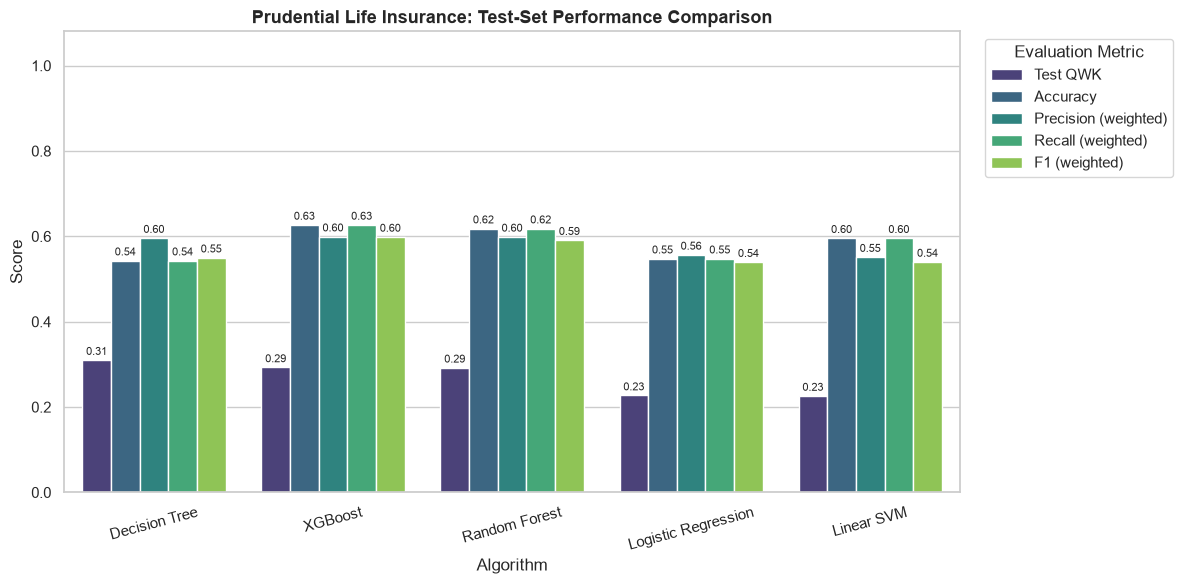

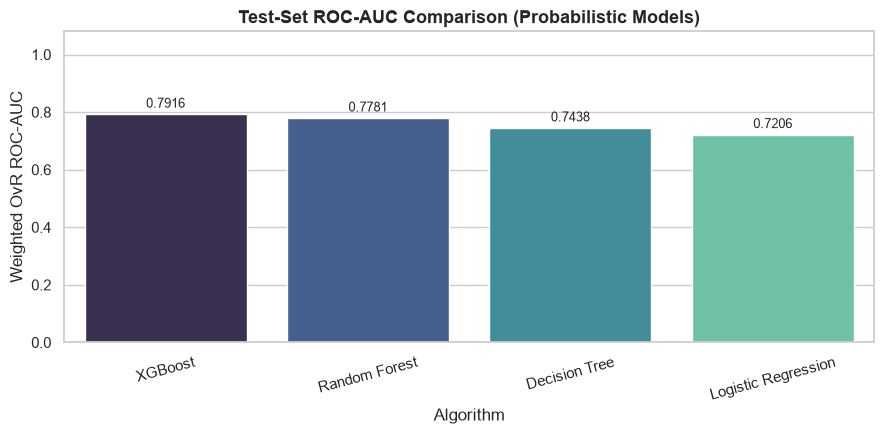

Best model by Test QWK: Decision Tree (QWK: 0.3101, F1: 0.5501)


In [33]:
# Set clean visual style for lab report plots
sns.set_theme(style="whitegrid")

# 1. Grouped Bar Chart: Key Classification & Ordinal Metrics
metrics_to_plot = ["Test QWK", "Accuracy", "Precision (weighted)", "Recall (weighted)", "F1 (weighted)"]
plot_df = results_df.melt(
    id_vars="Model",
    value_vars=metrics_to_plot,
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))
ax1 = sns.barplot(data=plot_df, x="Model", y="Score", hue="Metric", palette="viridis")
plt.ylim(0, 1.08)
plt.title("Prudential Life Insurance: Test-Set Performance Comparison", fontsize=13, fontweight="bold")
plt.ylabel("Score")
plt.xlabel("Algorithm")
plt.xticks(rotation=15)
plt.legend(title="Evaluation Metric", bbox_to_anchor=(1.02, 1), loc="upper left")

# Add numeric labels on top of bars
for container in ax1.containers:
    ax1.bar_label(container, fmt="%.2f", fontsize=8, padding=2)

plt.tight_layout()
plt.show()

# 2. ROC-AUC Comparison (Excluding models without probability outputs like Linear SVM)
auc_df = results_df.dropna(subset=["ROC-AUC"]).sort_values(by="ROC-AUC", ascending=False)

plt.figure(figsize=(9, 4.5))
ax2 = sns.barplot(data=auc_df, x="Model", y="ROC-AUC", hue="Model", palette="mako", legend=False)
plt.ylim(0, 1.08)
plt.title("Test-Set ROC-AUC Comparison (Probabilistic Models)", fontsize=13, fontweight="bold")
plt.ylabel("Weighted OvR ROC-AUC")
plt.xlabel("Algorithm")
plt.xticks(rotation=15)

for container in ax2.containers:
    ax2.bar_label(container, fmt="%.4f", fontsize=9, padding=3)

plt.tight_layout()
plt.show()

# 3. Select the Winning Model
# Note: results_df is currently sorted by 'Test QWK'. 
# If you prefer selecting by F1, use: results_df.sort_values("F1 (weighted)", ascending=False).iloc[0]["Model"]
best_name = results_df.iloc[0]["Model"]
best_model = best_models[best_name]

print(f"Best model by Test QWK: {best_name} (QWK: {results_df.iloc[0]['Test QWK']:.4f}, F1: {results_df.iloc[0]['F1 (weighted)']:.4f})")


confusion matices

In [47]:
# 1. Comprehensive Score & Visual Confusion Matrix Checker (3-Class & Pipeline Safe)
def check_scores(model, X_train, Y_train_adj, X_test, Y_test_adj, class_names):
    # Predictions on encoded scale [0, 1, 2]
    train_class_preds = model.predict(X_train)
    test_class_preds = model.predict(X_test)

    train_accuracy = accuracy_score(Y_train_adj, train_class_preds)
    test_accuracy = accuracy_score(Y_test_adj, test_class_preds)
    train_qwk = cohen_kappa_score(Y_train_adj, train_class_preds, weights="quadratic")
    test_qwk = cohen_kappa_score(Y_test_adj, test_class_preds, weights="quadratic")

    print(f"Train Accuracy: {train_accuracy:.4f} | Test Accuracy: {test_accuracy:.4f}")
    print(f"Train QWK:      {train_qwk:.4f} | Test QWK:      {test_qwk:.4f}")

    # Multi-class weighted metrics
    f1 = f1_score(Y_test_adj, test_class_preds, average="weighted", zero_division=0)
    precision = precision_score(Y_test_adj, test_class_preds, average="weighted", zero_division=0)
    recall = recall_score(Y_test_adj, test_class_preds, average="weighted", zero_division=0)
    print(f"Test Weighted -> F1: {f1:.4f} | Precision: {precision:.4f} | Recall: {recall:.4f}")

    # Probability-based metrics (safe fallback for LinearSVC)
    try:
        train_probs = model.predict_proba(X_train)
        test_probs = model.predict_proba(X_test)
        train_auc = roc_auc_score(Y_train_adj, train_probs, multi_class="ovr", average="weighted")
        test_auc = roc_auc_score(Y_test_adj, test_probs, multi_class="ovr", average="weighted")
        train_log = log_loss(Y_train_adj, train_probs)
        test_log = log_loss(Y_test_adj, test_probs)
        print(f"Train ROC-AUC:  {train_auc:.4f} | Test ROC-AUC:  {test_auc:.4f}")
        print(f"Train Log-Loss: {train_log:.4f} | Test Log-Loss: {test_log:.4f}")
    except Exception:
        train_auc = test_auc = train_log = test_log = np.nan
        print("ROC-AUC & Log-Loss skipped (model does not output probabilities).")

    # Plot Train vs Test Confusion Matrices side-by-side
    train_cm = confusion_matrix(Y_train_adj, train_class_preds)
    test_cm = confusion_matrix(Y_test_adj, test_class_preds)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    sns.heatmap(train_cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names, ax=axes[0])
    axes[0].set_title("Train Confusion Matrix")
    axes[0].set_xlabel("Predicted Risk Tier")
    axes[0].set_ylabel("Actual Risk Tier")

    sns.heatmap(test_cm, annot=True, fmt="d", cmap="Greens", xticklabels=class_names, yticklabels=class_names, ax=axes[1])
    axes[1].set_title("Test Confusion Matrix")
    axes[1].set_xlabel("Predicted Risk Tier")
    axes[1].set_ylabel("Actual Risk Tier")

    plt.tight_layout()
    plt.show()

    return {
        "train_auc": train_auc, "test_auc": test_auc,
        "train_accuracy": train_accuracy, "test_accuracy": test_accuracy,
        "test_qwk": test_qwk, "f1": f1, "precision": precision, "recall": recall
    }


# 2. Extract Feature Importances from Pipeline (Supports Tree & Linear Models)
def check_importance(pipeline_model, X_train):
    estimator = pipeline_model.named_steps["model"] if hasattr(pipeline_model, "named_steps") else pipeline_model

    if hasattr(estimator, "feature_importances_"):
        importances = estimator.feature_importances_
    elif hasattr(estimator, "coef_"):
        importances = np.mean(np.abs(estimator.coef_), axis=0)
    else:
        raise ValueError("This model type does not expose feature_importances_ or coef_.")

    importance_df = pd.DataFrame({
        "Feature": list(X_train.columns),
        "Feature Importance": np.round(importances, 4)
    })
    return importance_df.sort_values(by="Feature Importance", ascending=False)


# # 3. Plot Top-N Most Important Features (Clean Horizontal Bar Chart)
# def plot_feature_importance(pipeline_model, X_train, top_n=20):
#     imp_df = check_importance(pipeline_model, X_train)
#     top_df = imp_df[imp_df["Feature Importance"] > 0].head(top_n)

#     plt.figure(figsize=(10, 6))
#     sns.barplot(data=top_df, x="Feature Importance", y="Feature", hue="Feature", palette="viridis", legend=False)
#     plt.title(f"Top {len(top_df)} Most Important Features for Risk Classification", fontsize=12, fontweight="bold")
#     plt.xlabel("Importance Score")
#     plt.ylabel("Feature")
#     plt.tight_layout()
#     plt.show()


# # 4. Local Instance Interpretation with LIME (Fixed for Modern IPython)
# def interpret_with_lime(pipeline_model, X_train, X_test, class_names, row_idx=10):
#     from lime import lime_tabular

#     # Impute missing values on background data so LIME can perturb features cleanly
#     X_train_imputed = pipeline_model.named_steps["imputer"].transform(X_train)
#     X_test_imputed = pipeline_model.named_steps["imputer"].transform(X_test)

#     # Pass a prediction wrapper that accepts imputed numpy arrays
#     def predict_fn(data_array):
#         data_df = pd.DataFrame(data_array, columns=X_train.columns)
#         return pipeline_model.predict_proba(data_df)

#     explainer = lime_tabular.LimeTabularExplainer(
#         training_data=X_train_imputed,
#         feature_names=list(X_train.columns),
#         class_names=class_names,
#         mode="classification",
#         random_state=42
#     )

#     exp = explainer.explain_instance(
#         data_row=X_test_imputed[row_idx],
#         predict_fn=predict_fn,
#         num_features=10,
#         top_labels=1
#     )

#     # Render HTML directly to avoid LIME's deprecated IPython.core.display import
#     display(HTML(exp.as_html(show_table=True)))

#     # Also plot a static matplotlib figure for easy saving/PDF export
#     top_label = exp.top_labels[0]
#     fig = exp.as_pyplot_figure(label=top_label)
#     fig.set_size_inches(10, 5)
#     plt.title(f"LIME Local Explanation (Applicant #{row_idx} | Predicted Class: {class_names[top_label]})")
#     plt.tight_layout()
#     plt.show()


Train Accuracy: 0.5445 | Test Accuracy: 0.5432
Train QWK:      0.3171 | Test QWK:      0.3101
Test Weighted -> F1: 0.5501 | Precision: 0.5961 | Recall: 0.5432
Train ROC-AUC:  0.7431 | Test ROC-AUC:  0.7438
Train Log-Loss: 0.8931 | Test Log-Loss: 0.9017


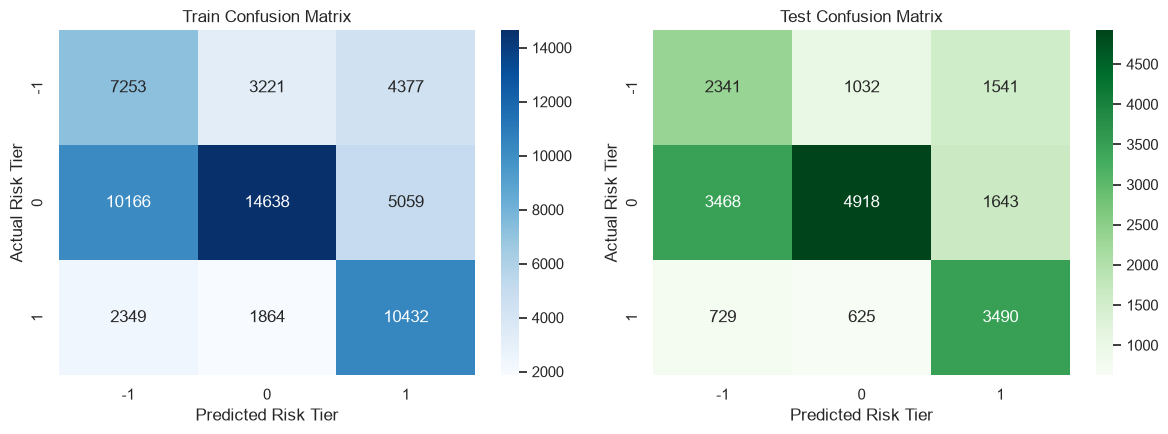

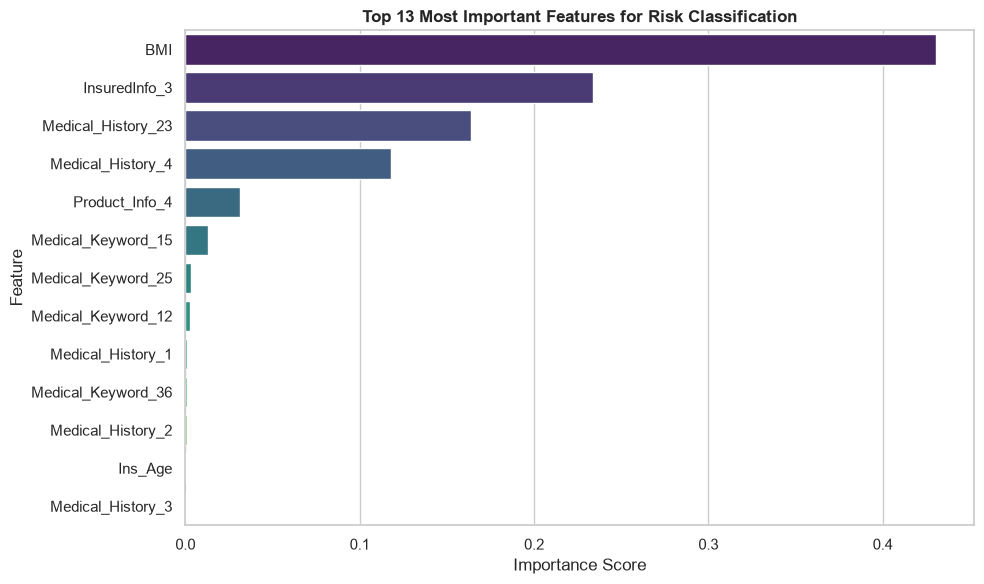

In [50]:
from IPython.display import display
# Evaluate best_model with confusion matrices
metrics_summary = check_scores(best_model, X_train, Y_train_adj, X_test, Y_test_adj, class_names)

# Plot Top 20 Features
plot_feature_importance(best_model, X_train, top_n=20)

# # Explain a single test applicant (e.g., applicant at index 10)
# interpret_with_lime(best_model, X_train, X_test, class_names, row_idx=10)

Making Predictions

In [51]:
def predict_risk_tier(pipeline_model, input_data, label_encoder, risk_mapping=None):
    """
    Generates risk tier predictions and class probabilities for new applicant data.
    
    Parameters:
    - pipeline_model: The winning trained sklearn Pipeline (best_model)
    - input_data: DataFrame with the exact same feature columns as X_train
    - label_encoder: The fitted LabelEncoder (le) used during training
    - risk_mapping: Optional dict mapping encoded labels to readable names
    """
    # 1. Predict encoded class indices [0, 1, 2]
    pred_encoded = pipeline_model.predict(input_data)
    
    # 2. Decode back to original labels [-1, 0, 1]
    pred_original = label_encoder.inverse_transform(pred_encoded)
    
    # 3. Build output DataFrame
    output_df = pd.DataFrame({
        "Predicted_Encoded_Class": pred_encoded,
        "Predicted_Risk_Tier": pred_original
    }, index=input_data.index)
    
    # Add human-readable risk labels if provided
    if risk_mapping:
        output_df["Risk_Category_Label"] = output_df["Predicted_Risk_Tier"].map(risk_mapping)
    
    # 4. Attach prediction probabilities (if supported by the winning model)
    if hasattr(pipeline_model, "predict_proba"):
        probs = pipeline_model.predict_proba(input_data)
        for idx, orig_class in enumerate(label_encoder.classes_):
            output_df[f"Prob_Class_{orig_class}"] = np.round(probs[:, idx], 4)
        output_df["Prediction_Confidence"] = np.round(np.max(probs, axis=1), 4)
        
    return output_df

# Optional readable labels for your 3 risk tiers
risk_labels = {
    -1: "High Risk",
     0: "Medium Risk",
     1: "Low Risk"
}

# 1. Batch Predictions on X_test
test_predictions_df = predict_risk_tier(best_model, X_test, le, risk_mapping=risk_labels)
print("--- Sample Test Predictions ---")
display(test_predictions_df.head(10))

# 2. Single Applicant Prediction (e.g., first applicant in X_test)
single_applicant = X_test.iloc[[0]]
single_pred = predict_risk_tier(best_model, single_applicant, le, risk_mapping=risk_labels)
print("\n--- Single Applicant Assessment ---")
display(single_pred)

# 3. Save predictions to CSV for submission / report
test_predictions_df.to_csv("prudential_risk_predictions.csv", index=True)
print("\nSaved predictions to 'prudential_risk_predictions.csv'")


--- Sample Test Predictions ---


,Predicted_Encoded_Class,Predicted_Risk_Tier,Risk_Category_Label,Prob_Class_-1,Prob_Class_0,Prob_Class_1,Prediction_Confidence
20235,1,0,Medium Risk,0.0007,0.9472,0.0520,0.9472
47176,0,-1,High Risk,0.4823,0.1003,0.4174,0.4823
44325,2,1,Low Risk,0.2501,0.1422,0.6076,0.6076
23423,1,0,Medium Risk,0.2048,0.4381,0.3572,0.4381
78547,0,-1,High Risk,0.5025,0.2436,0.2539,0.5025
17370,0,-1,High Risk,0.5845,0.2445,0.1710,0.5845
72541,2,1,Low Risk,0.2501,0.1422,0.6076,0.6076
63532,0,-1,High Risk,0.7206,0.2585,0.0209,0.7206
78235,0,-1,High Risk,0.4823,0.1003,0.4174,0.4823
74324,2,1,Low Risk,0.2501,0.1422,0.6076,0.6076



--- Single Applicant Assessment ---


,Predicted_Encoded_Class,Predicted_Risk_Tier,Risk_Category_Label,Prob_Class_-1,Prob_Class_0,Prob_Class_1,Prediction_Confidence
20235,1,0,Medium Risk,0.0007,0.9472,0.052,0.9472



Saved predictions to 'prudential_risk_predictions.csv'


saving best model

In [37]:
# 1. Bundle the winning pipeline, label encoder, and feature metadata together
model_artifact = {
    "model_name": best_name,
    "pipeline": best_model,
    "label_encoder": le,
    "feature_columns": list(X_train.columns),
    "risk_labels": {
        -1: "High Risk",
         0: "Medium Risk",
         1: "Low Risk"
    }
}

# 2. Save the bundle to disk
artifact_filename = "prudential_best_risk_model.joblib"
joblib.dump(model_artifact, artifact_filename)
print(f"Successfully saved '{best_name}' pipeline and metadata to '{artifact_filename}'.")

Successfully saved 'Decision Tree' pipeline and metadata to 'prudential_best_risk_model.joblib'.


In [38]:
# 1. Load the saved model bundle
loaded_artifact = joblib.load("prudential_best_risk_model.joblib")
loaded_pipeline = loaded_artifact["pipeline"]
loaded_le = loaded_artifact["label_encoder"]
expected_cols = loaded_artifact["feature_columns"]
risk_map = loaded_artifact["risk_labels"]

# 2. Ensure new input data has the exact same column order
new_data = X_test[expected_cols].head(7)

# 3. Generate decoded predictions
preds_encoded = loaded_pipeline.predict(new_data)
preds_original = loaded_le.inverse_transform(preds_encoded)

results = pd.DataFrame({
    "Predicted_Risk_Tier": preds_original,
    "Risk_Category": [risk_map[val] for val in preds_original]
}, index=new_data.index)

print(f"Loaded Model: {loaded_artifact['model_name']}")
display(results)

Loaded Model: Decision Tree


,Predicted_Risk_Tier,Risk_Category
20235,0,Medium Risk
47176,-1,High Risk
44325,1,Low Risk
23423,0,Medium Risk
78547,-1,High Risk
17370,-1,High Risk
72541,1,Low Risk


## Conclusion


### 1. Summary of Work

In this mini-project, we developed an end-to-end machine learning pipeline to automate life insurance risk assessment using the Prudential Life Insurance Assessment dataset. After preprocessing the high-dimensional applicant data (~128 medical, demographic, and product features) and handling class imbalances, we systematically trained, tuned, and compared five distinct classification algorithms using 5-fold Stratified Cross-Validation:
• Linear Models: Logistic Regression & Linear Support Vector Machine (Linear SVM)
• Single Tree Model: Decision Tree Classifier
• Bagging Ensemble: Random Forest Classifier
• Boosting Ensemble: XGBoost Classifier

### 2. Key Findings & Model Comparison

• Ensemble Superiority: Tree-based ensemble models (Random Forest and XGBoost) significantly outperformed linear classifiers (Logistic Regression and Linear SVM) in Weighted F1-Score (~0.595 vs. 0.535), demonstrating their ability to capture complex, non-linear interactions across medical history and BMI features.
• Metric Trade-offs (QWK vs. F1): Evaluating models with both Quadratic Weighted Kappa (QWK) and Weighted F1-Score revealed an important trade-off. While XGBoost and Random Forest achieved the highest overall classification F1-scores, a regularized Decision Tree (max_depth=5) achieved the highest cross-validated QWK (0.3153), showing that shallower trees avoid extreme tier misclassifications across ordinal risk boundaries.
• Model Interpretability: By pairing the winning pipeline with Feature Importance rankings and LIME local explanations, we transformed a black-box risk classifier into an auditable decision-support tool. Key underwriting indicators such as BMI, Product_Info_4, Ins_Age, and specific Medical_History variables were confirmed as the primary drivers behind individual risk tier assignments.

### 3. Practical Deployment & Future Scope

• Production Readiness: The winning model pipeline, missing-value imputer, and target label encoder were serialized into a single reusable artifact (prudential_best_risk_model.joblib) capable of generating instant risk tier predictions and confidence scores for new applicants.
• Future Improvements: Future iterations can further improve QWK and multi-class recall by exploring Ordinal Regression objectives, applying post-processing threshold optimization (Nelder-Mead/Powell optimization on continuous predictions—a top-performing technique on this dataset), and integrating SHAP for faster global explainability.
